## **Funções**

### Importação das Bibliotecas

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import os
import unicodedata 

### Função para realizar a normalização dos nomes das cidades para caixa alta e sem acento

In [3]:
def normalizar_texto(texto):

    if not isinstance(texto, str):
        return ""
    
    # Separa os acentos das letras
    texto_normalizado = unicodedata.normalize('NFKD', texto)

    # Conversão para ASCII ignorando os acentos
    texto_ascii = texto_normalizado.encode('ASCII', 'ignore').decode('ASCII')

    #Transformação das letras em maiúsculas
    texto = texto_ascii.upper().strip()

    return texto

### Função para leitura das bases de dados SISVAN

In [4]:
def leitura_dados_sisvan(uf, pasta_origem=".", anos = [2020, 2021, 2022, 2023, 2024, 2025]):

    lista_dfs = []

    colunas_qtd = [ 'Baixo peso','Adequado','Sobrepeso', 'Obesidade Grau I', 'Obesidade Grau II', 'Obesidade Grau III', 'Total']

    colunas_porcentagem = ['Obesidade Grau I %', 'Obesidade Grau II %', 'Obesidade Grau III %']

    for ano in anos:
        # Leitura dos arquivos em excel

        caminho = os.path.join(pasta_origem, f'RelatorioEstadoNutricional {ano} {uf}.xls.xlsx')

        if not os.path.exists(caminho):
            print(f'Aviso: Ficheiro não encontrado -> {caminho}')
            continue

        df_ano = pd.read_excel(caminho, header=1)

        # Remove espaços em branco antes e depois do nome de todas as colunas
        df_ano.columns = df_ano.columns.astype(str).str.strip()

        # Acrescenta a coluna do ano da base de dados
        df_ano['ano'] = ano

        # Cria a coluna municipio_norm e aplica a normalização no nome dos municípios
        df_ano['municipio_norm'] = df_ano['Município'].apply(normalizar_texto)

        # Altera o tipo de dados das colunas de quantidades para numérico

        for coluna in colunas_qtd:
            df_ano[coluna] = pd.to_numeric(df_ano[coluna], errors='coerce')


        # Tratamento da coluna de dados que possuem o símbolo de porcentagem nas células
        
        for coluna in colunas_porcentagem:
            # Tipo da coluna é string
            df_ano[coluna] = df_ano[coluna].astype(str)

            # Remoção do símbolo de porcentagem
            df_ano[coluna] = df_ano[coluna].str.replace('%', '', regex=False).str.replace(',', '.', regex=False).str.strip()

            # Conversão para float
            df_ano[coluna] = pd.to_numeric(df_ano[coluna], errors='coerce')

            # Verifica se há alguma célula fora do padrão de 100%
            condicao = (df_ano[coluna] > 0) & (df_ano[coluna] <= 1)

            df_ano.loc[condicao, coluna] = df_ano[coluna] * 100

            df_ano[coluna] = df_ano[coluna].round(2)

        # Cria colunas com o valor total de obesidade por cidade e taxa de obesidade
        
        df_ano['obesidade_total'] = df_ano['Obesidade Grau I'] + df_ano['Obesidade Grau II'] + df_ano['Obesidade Grau III']

        df_ano['obesidade_total_%'] = ((df_ano['obesidade_total'] / df_ano['Total']) * 100).round(2)

        lista_dfs.append(df_ano)

    return pd.concat(lista_dfs, ignore_index=True)

### Função para leitura de dados do IDHM

In [5]:
def leitura_idhm(uf, pasta_origem = '5 - IDHM'):

    caminho_idhm = os.path.join(pasta_origem,f'IDHM - {uf}.xlsx')
    df_idhm = pd.read_excel(caminho_idhm)

    # Tratamento e normalização dos nomes dos municípios
    df_idhm['municipio_norm'] = df_idhm['Municípios'].apply(normalizar_texto)

    # Mudança do tipo de dados da coluna IDHM para numérico
    df_idhm['idhm_2010'] = pd.to_numeric(df_idhm['Índice de Desenvolvimento Humano Municipal (IDHM)'], errors='coerce')

    # Categorização nas faixas do PNUD
    faixas = [0.0, 0.499, 0.599, 0.699, 0.799, 1.0]
    rotulos = ['Muito Baixo', 'Baixo', 'Médio', 'Alto', 'Muito Alto']

    df_idhm['faixa_idhm'] = pd.cut(df_idhm['idhm_2010'], bins=faixas, labels=rotulos)

    return df_idhm

### Função para selecionar as colunas dos dados SISVAN que serão utilizadas no merge entre SISVAN e IDHM

In [6]:
def selecionar_colunas_merge(df):

    colunas_desejadas = ['ano', 'UF', 'Código IBGE','municipio_norm', 'Baixo peso', 'Adequado', 'Sobrepeso', 'Obesidade Grau I', 'Obesidade Grau II', 'Obesidade Grau III', 'Total', 'obesidade_total', 'obesidade_total_%', 'Obesidade Grau I %', 'Obesidade Grau II %', 'Obesidade Grau III %',]

    df_sisvan_limpo = df[colunas_desejadas].copy()

    return df_sisvan_limpo


### Função para leitura de valores zerados

In [7]:
def identificar_valores_zerados(df, coluna):

    df_zerados = df[df[coluna] == 0].copy()

    return df_zerados

### Função para leitura de valores nulos

In [8]:
def identificar_valores_nulos(df, coluna):
    
    df_nulos = df[df [coluna].isna()].copy()

    return df_nulos

### Função para fazer o cruzamentos de dados entre SISVAN e IDHM

In [9]:
def integrar_sisvan_idhm(df_sisvan, df_idhm):
    df_integrado = pd.merge(
        df_sisvan,
        df_idhm[['municipio_norm', 'idhm_2010', 'faixa_idhm']],
        on='municipio_norm',
        how = 'inner'
    )
    return df_integrado

### Função para verificar o número de municípios em cada faixa de IDHM (como o IDHM é de 2010 a faixa é igual para todos os anos)

In [10]:
def municipios_por_faixa_IDHM(df):

    contagem_df = (df.groupby(['faixa_idhm'])['municipio_norm'].nunique().reset_index())

    contagem_df.columns = ['Faixa de IDHM', 'Qtd Municípios']

    return contagem_df

### Função para análise exploratória agregada no período 2020-2025

In [11]:
def comparar_idhm (df):
  
    comparacao_idhm = df.groupby('faixa_idhm').agg(
        qtd_municipios=('municipio_norm', 'nunique'),
        qtd_observacoes=('municipio_norm', 'count'),
        media_obesidade=('obesidade_total_%', 'mean'),
        mediana_obesidade=('obesidade_total_%', 'median'),
        desvio_obesidade =('obesidade_total_%', 'std'),
        maximo_obesidade =('obesidade_total_%', 'max'),
        minimo_obesidade =('obesidade_total_%', 'min')

    ).round(2).reset_index()


    # Exibe o resultado formatado
    comparacao_idhm = comparacao_idhm.rename(columns={
        'faixa_idhm': 'Faixa do IDHM',
        'qtd_municipios': 'Número de Municípios',
        'qtd_observacoes': 'Número de observações (2020-2025)',
        'media_obesidade': 'Média da Taxa de Obesidade (%)',
        'mediana_obesidade': 'Mediana da Taxa de Obesidade (%)', 
        'desvio_obesidade': 'Desvio-padrão da Taxa de Obesidade (%)',
        'maximo_obesidade': 'Valor máximo da Taxa de Obesidade (%)',
        'minimo_obesidade': 'Valor mínimo da Taxa de Obesidade (%)'
    })

    return comparacao_idhm

### Função para analisar a Média Anual da Taxa de Obesidade em cada Faixa de IDHM

In [12]:
def media_anual_obesidade(df):
    evolucao_anual = df.groupby(['faixa_idhm', 'ano'])['obesidade_total_%'].mean().unstack()

    # Arredonda para 2 casas decimais
    return evolucao_anual.round(2)

### Função para analisar a Mediana Anual da Taxa de Obesidade em cada Faixa de IDHM

In [13]:
def mediana_anual_obesidade(df):
    evolucao_anual_mediana = df.groupby(['faixa_idhm', 'ano'])['obesidade_total_%'].median().unstack()

    # Arredonda para 2 casas decimais
    return evolucao_anual_mediana.round(2)

### Função para criar o Gráfico de Dispersão IDHM x Obesidade

In [14]:
def grafico_IDHM_Obesidade(df, uf):

    df_municipio = (df.groupby(['municipio_norm', 'idhm_2010'])['obesidade_total_%'].mean().reset_index())

    # Seleção e remoção de valores nulos das colunas
    df_valido = df_municipio[['idhm_2010', 'obesidade_total_%']].dropna()

    x = df_valido['idhm_2010']
    y = df_valido['obesidade_total_%']

    #  Cálculo da linha de tendência 
    m, b = np.polyfit(x, y, 1)

    # Construção do gráfico com Matplotlib
    plt.figure(figsize=(7, 4))

    # Ponto de dispersão
    plt.scatter(x, y, alpha=0.4, color="#1b8bdb", label='Municípios')

    # Linha de tendência
    plt.plot(x, m * x + b, color='red', linewidth=2, label=f'Tendência')

    # Plotagem do gráfico
    plt.title(f'Dispersão: IDHM (2010) vs. Taxa de Obesidade (%) - {uf}', fontsize=12, fontweight='bold', pad=12)
    plt.xlabel('IDHM (2010)', fontsize=11)
    plt.ylabel('Taxa de Obesidade (%)', fontsize=11)
    plt.grid(True, linestyle='--', alpha=0.6)

    plt.legend(
        title='Legenda',
        bbox_to_anchor=(1.02, 1),
        loc='upper left',
        borderaxespad=0,
    )

    plt.tight_layout()
    plt.show()

### Função para analisar a média da Taxa de Obesidade a partir dos Graus em cada Faixa de IDHM  2020 - 2025

In [15]:
def analise_por_grau_obesidade(df, uf):
    grupo_grau_de_obesidade = df.groupby('faixa_idhm')[['Obesidade Grau I %', 'Obesidade Grau II %','Obesidade Grau III %']].mean().round(2)

    return grupo_grau_de_obesidade.style.format("{:.2f}").set_caption(f"Evolução Média dos Graus de Obesidade (%) por Faixa de IDHM (2020-2025) {uf}").set_table_styles([{'selector': 'caption', 'props': [('font-weight', 'bold'), ('font-size', '11pt')]}])

### Função para analisar a evolução anual de um Grau específico de obesidade em relação as faixas de IDHM

In [16]:
def evolucao_anual_grau(df, coluna, uf):
    evolucao_anual_GrauI = df.groupby(['faixa_idhm', 'ano'])[coluna].mean().unstack()

    return evolucao_anual_GrauI.style.format("{:.2f}").set_caption(f"Evolução da {coluna} por Faixa de IDHM {uf}").set_table_styles([{'selector': 'caption','props':[('font-weight', 'bold'), ('font-size', '11pt')]}])

### Função para analisar a prevalência agregada de obesidade entre os indivíduos avaliados no SISVAN e construção do gráfico

In [146]:
def grafico_prevalencia(df, uf):
    df_pivot = df['prevalencia %'].unstack()

    plt.figure(figsize=(9, 4))

    faixas = ['Baixo', 'Médio', 'Alto', 'Muito Alto']

    for faixa in faixas:
        if faixa in df_pivot.columns:
            plt.plot(
                df_pivot.index,
                df_pivot[faixa],
                marker='o',
                linewidth=2.5,
                label=f'IDHM {faixa}',
            )

    plt.title(
        f'Prevalência agregada de obesidade entre os indivíduos avaliados no SISVAN ({uf})',
        fontsize=11,
        fontweight='bold',
        pad=10,
    )
    plt.xlabel('Ano', fontsize=11)
    plt.ylabel('Prevalência de Obesidade (%)', fontsize=11)

    plt.ylim(18, 48)
    plt.xticks(df_pivot.index)
    plt.grid(True, linestyle='--', alpha=0.5)

    plt.legend(
        title='Faixa IDHM',
        bbox_to_anchor=(1.02, 1),
        loc='upper left',
        borderaxespad=0,
    )

    plt.tight_layout()
    plt.show()

In [139]:
def prevalencia_agregada(df, uf):

    totais_por_faixa = df.groupby(['ano', 'faixa_idhm'])[['obesidade_total', 'Total']].sum()

    totais_por_faixa['prevalencia %'] = (totais_por_faixa['obesidade_total'] / totais_por_faixa['Total'] * 100).round(2)

    grafico_prevalencia(totais_por_faixa, uf)

    return totais_por_faixa

In [168]:
def prevalencia_agregada_sudeste(df):

    totais_por_faixa = df.groupby(['ano', 'faixa_idhm'])[['obesidade_total', 'Total']].sum()

    totais_por_faixa['prevalencia %'] = (totais_por_faixa['obesidade_total'] / totais_por_faixa['Total'] * 100).round(2)

    grafico_prevalencia(totais_por_faixa, "")

    return totais_por_faixa

### Função para listar os nomes dos municípios em cada uma das faixas de IDHM

In [19]:
def nome_municipio_por_IDHM (df, faixa):
    
    cidades_idhm = df[(df['faixa_idhm'] == faixa) & (df ['ano'] == 2020)][['municipio_norm', 'faixa_idhm', 'idhm_2010']]

    if cidades_idhm.empty:
        print(f"Aviso: Não existem municípios cadastrados na faixa de IDHM '{faixa}' para este estado.")
        return None

    return cidades_idhm

    '''print(cidades_idhm['municipio_norm'].tolist())

    with pd.option_context('display.max_rows', None):
    display(cidades_idhm)'''

## **Coleta e preparação dos Dados**

### Leitura dos dados SISVAN de cada Estado da Região Sudeste

In [20]:
df_sisvan_es = leitura_dados_sisvan(uf= 'ES', pasta_origem = '1 - ES')

df_sisvan_es

,Região,Código UF,UF,Código IBGE,Município,Baixo peso,Baixo peso %,Adequado,Adequado %,Sobrepeso,...,Obesidade Grau I %,Obesidade Grau II,Obesidade Grau II %,Obesidade Grau III,Obesidade Grau III %,Total,ano,municipio_norm,obesidade_total,obesidade_total_%
0,SUDESTE,32,ES,320010,AFONSO CLAUDIO,21,2.64%,253,31.82%,279,...,16.86,62,7.80,46,5.79,795,2020,AFONSO CLAUDIO,242,30.44
1,SUDESTE,32,ES,320016,AGUA DOCE DO NORTE,12,1.67%,226,31.48%,221,...,23.12,54,7.52,39,5.43,718,2020,AGUA DOCE DO NORTE,259,36.07
2,SUDESTE,32,ES,320013,AGUIA BRANCA,3,1.97%,49,32.24%,55,...,14.47,11,7.24,12,7.89,152,2020,AGUIA BRANCA,45,29.61
3,SUDESTE,32,ES,320020,ALEGRE,26,2.37%,414,37.7%,332,...,18.21,83,7.56,43,3.92,1098,2020,ALEGRE,326,29.69
4,SUDESTE,32,ES,320030,ALFREDO CHAVES,12,0.02,197,32.89%,207,...,18.86,48,8.01,22,3.67,599,2020,ALFREDO CHAVES,183,30.55
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
463,SUDESTE,32,ES,320510,VIANA,37,1.88%,454,23.09%,600,...,24.26,244,12.41,154,7.83,1966,2025,VIANA,875,44.51
464,SUDESTE,32,ES,320515,VILA PAVAO,9,0.98%,237,25.87%,320,...,23.69,85,9.28,48,5.24,916,2025,VILA PAVAO,350,38.21
465,SUDESTE,32,ES,320517,VILA VALERIO,10,1.53%,166,25.46%,188,...,27.30,69,10.58,41,6.29,652,2025,VILA VALERIO,288,44.17
466,SUDESTE,32,ES,320520,VILA VELHA,664,1.72%,9394,24.4%,12410,...,23.49,4292,11.15,2693,7.00,38498,2025,VILA VELHA,16030,41.64


In [21]:
df_sisvan_mg = leitura_dados_sisvan(uf='MG', pasta_origem='2 - MG')

df_sisvan_mg

,Região,Código UF,UF,Código IBGE,Município,Baixo peso,Baixo peso %,Adequado,Adequado %,Sobrepeso,...,Obesidade Grau I %,Obesidade Grau II,Obesidade Grau II %,Obesidade Grau III,Obesidade Grau III %,Total,ano,municipio_norm,obesidade_total,obesidade_total_%
0,SUDESTE,31,MG,310010,ABADIA DOS DOURADOS,26,2.47%,353,33.49%,325,...,18.79,98,9.30,54,5.12,1054,2020,ABADIA DOS DOURADOS,350,33.21
1,SUDESTE,31,MG,310020,ABAETE,61,2.2%,843,30.41%,943,...,21.00,226,8.15,117,4.22,2772,2020,ABAETE,925,33.37
2,SUDESTE,31,MG,310030,ABRE CAMPO,40,2.65%,546,36.18%,516,...,17.89,108,7.16,29,1.92,1509,2020,ABRE CAMPO,407,26.97
3,SUDESTE,31,MG,310040,ACAIACA,3,1.94%,44,28.39%,40,...,25.81,14,9.03,14,9.03,155,2020,ACAIACA,68,43.87
4,SUDESTE,31,MG,310050,ACUCENA,32,1.91%,554,33.13%,579,...,18.18,141,8.43,62,3.71,1672,2020,ACUCENA,507,30.32
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
5113,SUDESTE,31,MG,317180,VIRGINOPOLIS,37,1.72%,609,28.23%,735,...,22.99,192,8.90,88,4.08,2157,2025,VIRGINOPOLIS,776,35.98
5114,SUDESTE,31,MG,317190,VIRGOLANDIA,23,1.46%,457,29.11%,609,...,19.49,110,7.01,65,4.14,1570,2025,VIRGOLANDIA,481,30.64
5115,SUDESTE,31,MG,317200,VISCONDE DO RIO BRANCO,128,1.62%,2274,28.85%,2626,...,20.70,745,9.45,477,6.05,7881,2025,VISCONDE DO RIO BRANCO,2853,36.20
5116,SUDESTE,31,MG,317210,VOLTA GRANDE,23,1.56%,380,25.8%,481,...,23.49,148,10.05,95,6.45,1473,2025,VOLTA GRANDE,589,39.99


In [22]:
df_sisvan_rj = leitura_dados_sisvan(uf= 'RJ', pasta_origem= '3 - RJ')

df_sisvan_rj

,Região,Código UF,UF,Código IBGE,Município,Baixo peso,Baixo peso %,Adequado,Adequado %,Sobrepeso,...,Obesidade Grau I %,Obesidade Grau II,Obesidade Grau II %,Obesidade Grau III,Obesidade Grau III %,Total,ano,municipio_norm,obesidade_total,obesidade_total_%
0,SUDESTE,33,RJ,330010,ANGRA DOS REIS,125,1.98%,1816,28.73%,2066,...,22.20,588,9.30,322,5.09,6320,2020,ANGRA DOS REIS,2313,36.60
1,SUDESTE,33,RJ,330015,APERIBE,11,2.06%,135,25.23%,188,...,21.31,56,10.47,31,5.79,535,2020,APERIBE,201,37.57
2,SUDESTE,33,RJ,330020,ARARUAMA,47,3.25%,391,27.04%,413,...,22.27,178,12.31,95,6.57,1446,2020,ARARUAMA,595,41.15
3,SUDESTE,33,RJ,330022,AREAL,15,3.97%,91,24.07%,112,...,21.43,44,11.64,35,9.26,378,2020,AREAL,160,42.33
4,SUDESTE,33,RJ,330023,ARMACAO DOS BUZIOS,15,1.69%,220,24.83%,292,...,25.06,82,9.26,55,6.21,886,2020,ARMACAO DOS BUZIOS,359,40.52
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
547,SUDESTE,33,RJ,330600,TRES RIOS,179,1.96%,2165,23.69%,3067,...,23.56,972,10.64,603,6.60,9139,2025,TRES RIOS,3728,40.79
548,SUDESTE,33,RJ,330610,VALENCA,281,2.54%,3145,28.38%,3462,...,21.84,1130,10.20,644,5.81,11082,2025,VALENCA,4194,37.85
549,SUDESTE,33,RJ,330615,VARRE-SAI,26,1.61%,484,29.97%,537,...,21.42,134,8.30,88,5.45,1615,2025,VARRE-SAI,568,35.17
550,SUDESTE,33,RJ,330620,VASSOURAS,152,2.15%,1822,25.71%,2253,...,23.24,761,10.74,451,6.36,7086,2025,VASSOURAS,2859,40.35


In [23]:
df_sisvan_sp = leitura_dados_sisvan(uf='SP', pasta_origem= '4 - SP')

df_sisvan_sp

,Região,Código UF,UF,Código IBGE,Município,Baixo peso,Baixo peso %,Adequado,Adequado %,Sobrepeso,...,Obesidade Grau I %,Obesidade Grau II,Obesidade Grau II %,Obesidade Grau III,Obesidade Grau III %,Total,ano,municipio_norm,obesidade_total,obesidade_total_%
0,SUDESTE,35,SP,350010,ADAMANTINA,72,1.69%,1048,24.6%,1460,...,23.52,418,9.81,261,6.13,4261,2020,ADAMANTINA,1681,39.45
1,SUDESTE,35,SP,350020,ADOLFO,0,-,12,13.95%,25,...,29.07,11,12.79,13,15.12,86,2020,ADOLFO,49,56.98
2,SUDESTE,35,SP,350030,AGUAI,31,2.2%,313,22.18%,422,...,26.29,159,11.27,115,8.15,1411,2020,AGUAI,645,45.71
3,SUDESTE,35,SP,350040,AGUAS DA PRATA,0,-,0,-,0,...,NaN,0,NaN,0,NaN,0,2020,AGUAS DA PRATA,0,NaN
4,SUDESTE,35,SP,350050,AGUAS DE LINDOIA,20,1.78%,307,27.36%,407,...,20.86,94,8.38,60,5.35,1122,2020,AGUAS DE LINDOIA,388,34.58
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3865,SUDESTE,35,SP,355690,VISTA ALEGRE DO ALTO,29,1.28%,531,23.42%,770,...,22.85,253,11.16,166,7.32,2267,2025,VISTA ALEGRE DO ALTO,937,41.33
3866,SUDESTE,35,SP,355695,VITORIA BRASIL,6,0.79%,152,19.92%,254,...,26.34,87,11.40,63,8.26,763,2025,VITORIA BRASIL,351,46.00
3867,SUDESTE,35,SP,355700,VOTORANTIM,114,2.23%,1252,24.45%,1630,...,23.09,567,11.07,375,7.32,5120,2025,VOTORANTIM,2124,41.48
3868,SUDESTE,35,SP,355710,VOTUPORANGA,360,1.52%,5238,22.1%,7996,...,23.90,2769,11.69,1669,7.04,23696,2025,VOTUPORANGA,10102,42.63


### Verificação de valores zerados na coluna Obesidade Total 2020 - 2025

In [24]:
valores_zerados_es = identificar_valores_zerados(df_sisvan_es, 'obesidade_total')

valores_zerados_es

,Região,Código UF,UF,Código IBGE,Município,Baixo peso,Baixo peso %,Adequado,Adequado %,Sobrepeso,...,Obesidade Grau I %,Obesidade Grau II,Obesidade Grau II %,Obesidade Grau III,Obesidade Grau III %,Total,ano,municipio_norm,obesidade_total,obesidade_total_%


In [25]:
valores_zerados_mg = identificar_valores_zerados(df_sisvan_mg, 'obesidade_total')

valores_zerados_mg

# Minas Gerais possui uma cidade com valor zerado

,Região,Código UF,UF,Código IBGE,Município,Baixo peso,Baixo peso %,Adequado,Adequado %,Sobrepeso,...,Obesidade Grau I %,Obesidade Grau II,Obesidade Grau II %,Obesidade Grau III,Obesidade Grau III %,Total,ano,municipio_norm,obesidade_total,obesidade_total_%
1394,SUDESTE,31,MG,314625,PADRE CARVALHO,0,-,23,0.92,2,...,NaN,0,NaN,0,NaN,25,2021,PADRE CARVALHO,0,0.0


In [26]:
valores_zerados_rj = identificar_valores_zerados(df_sisvan_rj, 'obesidade_total')

valores_zerados_rj

,Região,Código UF,UF,Código IBGE,Município,Baixo peso,Baixo peso %,Adequado,Adequado %,Sobrepeso,...,Obesidade Grau I %,Obesidade Grau II,Obesidade Grau II %,Obesidade Grau III,Obesidade Grau III %,Total,ano,municipio_norm,obesidade_total,obesidade_total_%


In [27]:
valores_zerados_sp = identificar_valores_zerados(df_sisvan_sp, 'obesidade_total')

valores_zerados_sp

# São Paulo possui valores zerados

,Região,Código UF,UF,Código IBGE,Município,Baixo peso,Baixo peso %,Adequado,Adequado %,Sobrepeso,...,Obesidade Grau I %,Obesidade Grau II,Obesidade Grau II %,Obesidade Grau III,Obesidade Grau III %,Total,ano,municipio_norm,obesidade_total,obesidade_total_%
3,SUDESTE,35,SP,350040,AGUAS DA PRATA,0,-,0,-,0,...,NaN,0,NaN,0,NaN,0,2020,AGUAS DA PRATA,0,NaN
81,SUDESTE,35,SP,350720,BORA,0,-,0,-,0,...,NaN,0,NaN,0,NaN,0,2020,BORA,0,NaN
130,SUDESTE,35,SP,351150,CERQUILHO,0,-,0,-,0,...,NaN,0,NaN,0,NaN,0,2020,CERQUILHO,0,NaN
306,SUDESTE,35,SP,352700,LINDOIA,0,-,0,-,0,...,NaN,0,NaN,0,NaN,0,2020,LINDOIA,0,NaN
366,SUDESTE,35,SP,353250,NEVES PAULISTA,0,-,2,1,0,...,NaN,0,NaN,0,NaN,2,2020,NEVES PAULISTA,0,0.0
377,SUDESTE,35,SP,353330,NOVA LUZITANIA,0,-,0,-,0,...,NaN,0,NaN,0,NaN,0,2020,NOVA LUZITANIA,0,NaN
379,SUDESTE,35,SP,353325,NOVAIS,0,-,1,1,0,...,NaN,0,NaN,0,NaN,1,2020,NOVAIS,0,0.0
508,SUDESTE,35,SP,354515,SALTINHO,0,-,0,-,0,...,NaN,0,NaN,0,NaN,0,2020,SALTINHO,0,NaN
648,SUDESTE,35,SP,350040,AGUAS DA PRATA,0,-,0,-,0,...,NaN,0,NaN,0,NaN,0,2021,AGUAS DA PRATA,0,NaN
658,SUDESTE,35,SP,350115,ALUMINIO,0,-,2,1,0,...,NaN,0,NaN,0,NaN,2,2021,ALUMINIO,0,0.0


### Verificação de valores Nulos na coluna Obesidade Total %

In [28]:
valores_nulos_es = identificar_valores_nulos(df_sisvan_es, 'obesidade_total_%')
valores_nulos_es

,Região,Código UF,UF,Código IBGE,Município,Baixo peso,Baixo peso %,Adequado,Adequado %,Sobrepeso,...,Obesidade Grau I %,Obesidade Grau II,Obesidade Grau II %,Obesidade Grau III,Obesidade Grau III %,Total,ano,municipio_norm,obesidade_total,obesidade_total_%


In [29]:
valores_nulos_mg = identificar_valores_nulos(df_sisvan_mg, 'obesidade_total_%')
valores_nulos_mg

,Região,Código UF,UF,Código IBGE,Município,Baixo peso,Baixo peso %,Adequado,Adequado %,Sobrepeso,...,Obesidade Grau I %,Obesidade Grau II,Obesidade Grau II %,Obesidade Grau III,Obesidade Grau III %,Total,ano,municipio_norm,obesidade_total,obesidade_total_%


In [30]:
valores_nulos_rj = identificar_valores_nulos(df_sisvan_rj, 'obesidade_total_%')
valores_nulos_rj

,Região,Código UF,UF,Código IBGE,Município,Baixo peso,Baixo peso %,Adequado,Adequado %,Sobrepeso,...,Obesidade Grau I %,Obesidade Grau II,Obesidade Grau II %,Obesidade Grau III,Obesidade Grau III %,Total,ano,municipio_norm,obesidade_total,obesidade_total_%


In [31]:
valores_nulos_sp = identificar_valores_nulos(df_sisvan_sp, 'obesidade_total_%')
valores_nulos_sp
#São Paulo possui valores nulos

,Região,Código UF,UF,Código IBGE,Município,Baixo peso,Baixo peso %,Adequado,Adequado %,Sobrepeso,...,Obesidade Grau I %,Obesidade Grau II,Obesidade Grau II %,Obesidade Grau III,Obesidade Grau III %,Total,ano,municipio_norm,obesidade_total,obesidade_total_%
3,SUDESTE,35,SP,350040,AGUAS DA PRATA,0,-,0,-,0,...,NaN,0,NaN,0,NaN,0,2020,AGUAS DA PRATA,0,NaN
81,SUDESTE,35,SP,350720,BORA,0,-,0,-,0,...,NaN,0,NaN,0,NaN,0,2020,BORA,0,NaN
130,SUDESTE,35,SP,351150,CERQUILHO,0,-,0,-,0,...,NaN,0,NaN,0,NaN,0,2020,CERQUILHO,0,NaN
306,SUDESTE,35,SP,352700,LINDOIA,0,-,0,-,0,...,NaN,0,NaN,0,NaN,0,2020,LINDOIA,0,NaN
377,SUDESTE,35,SP,353330,NOVA LUZITANIA,0,-,0,-,0,...,NaN,0,NaN,0,NaN,0,2020,NOVA LUZITANIA,0,NaN
508,SUDESTE,35,SP,354515,SALTINHO,0,-,0,-,0,...,NaN,0,NaN,0,NaN,0,2020,SALTINHO,0,NaN
648,SUDESTE,35,SP,350040,AGUAS DA PRATA,0,-,0,-,0,...,NaN,0,NaN,0,NaN,0,2021,AGUAS DA PRATA,0,NaN
1022,SUDESTE,35,SP,353330,NOVA LUZITANIA,0,-,0,-,0,...,NaN,0,NaN,0,NaN,0,2021,NOVA LUZITANIA,0,NaN
1072,SUDESTE,35,SP,353780,PIEDADE,0,-,0,-,0,...,NaN,0,NaN,0,NaN,0,2021,PIEDADE,0,NaN
1153,SUDESTE,35,SP,354515,SALTINHO,0,-,0,-,0,...,NaN,0,NaN,0,NaN,0,2021,SALTINHO,0,NaN


### Leitura de IDHM dos Estados do Sudeste Brasileiro

In [32]:
df_idhm_es = leitura_idhm('Espirito Santo')

df_idhm_es

,Municípios,Gentílico,Índice de Desenvolvimento Humano Municipal (IDHM),PIB per capita,Total de receitas brutas realizadas,Transferências correntes (Percentual em relação às receitas correntes brutas realizadas),municipio_norm,idhm_2010,faixa_idhm
0,Afonso Cláudio,capixaba ou espírito-santense,0.667,"24123,96 R$","178686346,81 R$","89,28 %",AFONSO CLAUDIO,0.667,Médio
1,Água Doce do Norte,capixaba ou espírito-santense,0.652,"19457,45 R$","80741677,66 R$","89,28 %",AGUA DOCE DO NORTE,0.652,Médio
2,Águia Branca,capixaba ou espírito-santense,0.678,"32288,9 R$","94555442,97 R$","83,2 %",AGUIA BRANCA,0.678,Médio
3,Alegre,capixaba ou espírito-santense,0.721,"24063,72 R$",186472355 R$,"75,22 %",ALEGRE,0.721,Alto
4,Alfredo Chaves,capixaba ou espírito-santense,0.710,"40863,32 R$","123833088,93 R$","77,34 %",ALFREDO CHAVES,0.710,Alto
...,...,...,...,...,...,...,...,...,...
73,Viana,capixaba ou espírito-santense,0.686,"81139,91 R$","568920125,07 R$","78,42 %",VIANA,0.686,Médio
74,Vila Pavão,capixaba ou espírito-santense,0.681,"23942,58 R$","76639581,81 R$","91,04 %",VILA PAVAO,0.681,Médio
75,Vila Valério,capixaba ou espírito-santense,0.675,"44849,39 R$","123624200,06 R$","90,61 %",VILA VALERIO,0.675,Médio
76,Vila Velha,capixaba ou espírito-santense,0.800,"42143,26 R$","2329267742,39 R$","52,54 %",VILA VELHA,0.800,Muito Alto


In [33]:
df_idhm_mg = leitura_idhm('Minas Gerais')

df_idhm_mg

,Municípios,Gentílico,Índice de Desenvolvimento Humano Municipal (IDHM),PIB per capita 2023,Total de receitas brutas realizadas 2025,Transferências correntes (Percentual em relação às receitas correntes brutas realizadas) 2025,municipio_norm,idhm_2010,faixa_idhm
0,Abadia dos Dourados,mineiro,0.689,"30356,59 R$","54056251,12 R$","90,95 %",ABADIA DOS DOURADOS,0.689,Médio
1,Abaeté,mineiro,0.698,"28311,84 R$","171110172,9 R$","82,77 %",ABAETE,0.698,Médio
2,Abre Campo,mineiro,0.654,"23803,57 R$","79952087,52 R$",85 %,ABRE CAMPO,0.654,Médio
3,Acaiaca,mineiro,0.630,"21761,55 R$","34605138,82 R$","93,97 %",ACAIACA,0.630,Médio
4,Açucena,mineiro,0.610,"19243,4 R$","48102705,27 R$","90,58 %",ACUCENA,0.610,Médio
...,...,...,...,...,...,...,...,...,...
848,Virginópolis,mineiro,0.675,"20456,87 R$","68103990,16 R$","84,83 %",VIRGINOPOLIS,0.675,Médio
849,Virgolândia,mineiro,0.620,"14883,22 R$","43157495,55 R$","95,64 %",VIRGOLANDIA,0.620,Médio
850,Visconde do Rio Branco,mineiro,0.709,"52407,5 R$","192408856,79 R$","80,5 %",VISCONDE DO RIO BRANCO,0.709,Alto
851,Volta Grande,mineiro,0.669,"32947,62 R$","42598966,31 R$","92,65 %",VOLTA GRANDE,0.669,Médio


In [34]:
df_idhm_rj = leitura_idhm('Rio de Janeiro')

df_idhm_rj

,Municípios,Gentílico,Índice de Desenvolvimento Humano Municipal (IDHM),PIB per capita,Total de receitas brutas realizadas,Transferências correntes (Percentual em relação às receitas correntes brutas realizadas),municipio_norm,idhm_2010,faixa_idhm
0,Angra dos Reis,fluminense,0.724,"71075,76 R$","2633501082,45 R$","58,94 %",ANGRA DOS REIS,0.724,Alto
1,Aperibé,fluminense,0.692,"27291,05 R$","114430356,13 R$","86,6 %",APERIBE,0.692,Médio
2,Araruama,fluminense,0.718,"101458,16 R$","1198076827,01 R$","80,62 %",ARARUAMA,0.718,Alto
3,Areal,fluminense,0.684,"50479,55 R$","155211071,14 R$","78,18 %",AREAL,0.684,Médio
4,Armação dos Búzios,fluminense,0.728,"125471,71 R$","633598126,29 R$","61,56 %",ARMACAO DOS BUZIOS,0.728,Alto
...,...,...,...,...,...,...,...,...,...
87,Três Rios,fluminense,0.725,"76808,47 R$","539925194,02 R$","72,76 %",TRES RIOS,0.725,Alto
88,Valença,fluminense,0.738,"45595,24 R$","416903724,1 R$","78,04 %",VALENCA,0.738,Alto
89,Varre-Sai,fluminense,0.659,"39964,25 R$",109707613 R$,"80,38 %",VARRE-SAI,0.659,Médio
90,Vassouras,fluminense,0.714,"43350,59 R$","314905773,73 R$","83,03 %",VASSOURAS,0.714,Alto


In [35]:
df_idhm_sp = leitura_idhm('São Paulo')

df_idhm_sp

,Municípios,Gentílico,Índice de Desenvolvimento Humano Municipal (IDHM),PIB per capita,Total de receitas brutas realizadas,Transferências correntes (Percentual em relação às receitas correntes brutas realizadas),municipio_norm,idhm_2010,faixa_idhm
0,Adamantina,paulista,0.790,"49179,66 R$","313833384,84 R$","51,73 %",ADAMANTINA,0.790,Alto
1,Adolfo,paulista,0.730,"49478,96 R$","50181541,52 R$","85,75 %",ADOLFO,0.730,Alto
2,Aguaí,paulista,0.715,"55308,14 R$","178612817,81 R$","82,87 %",AGUAI,0.715,Alto
3,Águas da Prata,paulista,0.781,"36960,06 R$","61132118,93 R$","66,24 %",AGUAS DA PRATA,0.781,Alto
4,Águas de Lindóia,paulista,0.745,"44680,12 R$","163353038,89 R$","51,93 %",AGUAS DE LINDOIA,0.745,Alto
...,...,...,...,...,...,...,...,...,...
640,Vista Alegre do Alto,paulista,0.744,"87056,5 R$","69193586,64 R$","82,76 %",VISTA ALEGRE DO ALTO,0.744,Alto
641,Vitória Brasil,paulista,0.725,"35942,63 R$","28525618,55 R$","93,71 %",VITORIA BRASIL,0.725,Alto
642,Votorantim,paulista,0.767,"40724,92 R$","653005119,04 R$","57,79 %",VOTORANTIM,0.767,Alto
643,Votuporanga,paulista,0.790,"47418,12 R$","646686502,89 R$","55,48 %",VOTUPORANGA,0.790,Alto


### Escolhas das colunas de dados SISVAN utilizadas no merge dos dados entre SISVAN e IDHM

In [36]:
df_es_limpo = selecionar_colunas_merge(df_sisvan_es)
df_es_limpo

,ano,UF,Código IBGE,municipio_norm,Baixo peso,Adequado,Sobrepeso,Obesidade Grau I,Obesidade Grau II,Obesidade Grau III,Total,obesidade_total,obesidade_total_%,Obesidade Grau I %,Obesidade Grau II %,Obesidade Grau III %
0,2020,ES,320010,AFONSO CLAUDIO,21,253,279,134,62,46,795,242,30.44,16.86,7.80,5.79
1,2020,ES,320016,AGUA DOCE DO NORTE,12,226,221,166,54,39,718,259,36.07,23.12,7.52,5.43
2,2020,ES,320013,AGUIA BRANCA,3,49,55,22,11,12,152,45,29.61,14.47,7.24,7.89
3,2020,ES,320020,ALEGRE,26,414,332,200,83,43,1098,326,29.69,18.21,7.56,3.92
4,2020,ES,320030,ALFREDO CHAVES,12,197,207,113,48,22,599,183,30.55,18.86,8.01,3.67
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
463,2025,ES,320510,VIANA,37,454,600,477,244,154,1966,875,44.51,24.26,12.41,7.83
464,2025,ES,320515,VILA PAVAO,9,237,320,217,85,48,916,350,38.21,23.69,9.28,5.24
465,2025,ES,320517,VILA VALERIO,10,166,188,178,69,41,652,288,44.17,27.30,10.58,6.29
466,2025,ES,320520,VILA VELHA,664,9394,12410,9045,4292,2693,38498,16030,41.64,23.49,11.15,7.00


In [37]:
df_mg_limpo = selecionar_colunas_merge(df_sisvan_mg)
df_mg_limpo

,ano,UF,Código IBGE,municipio_norm,Baixo peso,Adequado,Sobrepeso,Obesidade Grau I,Obesidade Grau II,Obesidade Grau III,Total,obesidade_total,obesidade_total_%,Obesidade Grau I %,Obesidade Grau II %,Obesidade Grau III %
0,2020,MG,310010,ABADIA DOS DOURADOS,26,353,325,198,98,54,1054,350,33.21,18.79,9.30,5.12
1,2020,MG,310020,ABAETE,61,843,943,582,226,117,2772,925,33.37,21.00,8.15,4.22
2,2020,MG,310030,ABRE CAMPO,40,546,516,270,108,29,1509,407,26.97,17.89,7.16,1.92
3,2020,MG,310040,ACAIACA,3,44,40,40,14,14,155,68,43.87,25.81,9.03,9.03
4,2020,MG,310050,ACUCENA,32,554,579,304,141,62,1672,507,30.32,18.18,8.43,3.71
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
5113,2025,MG,317180,VIRGINOPOLIS,37,609,735,496,192,88,2157,776,35.98,22.99,8.90,4.08
5114,2025,MG,317190,VIRGOLANDIA,23,457,609,306,110,65,1570,481,30.64,19.49,7.01,4.14
5115,2025,MG,317200,VISCONDE DO RIO BRANCO,128,2274,2626,1631,745,477,7881,2853,36.20,20.70,9.45,6.05
5116,2025,MG,317210,VOLTA GRANDE,23,380,481,346,148,95,1473,589,39.99,23.49,10.05,6.45


In [38]:
df_rj_limpo = selecionar_colunas_merge(df_sisvan_rj)
df_rj_limpo

,ano,UF,Código IBGE,municipio_norm,Baixo peso,Adequado,Sobrepeso,Obesidade Grau I,Obesidade Grau II,Obesidade Grau III,Total,obesidade_total,obesidade_total_%,Obesidade Grau I %,Obesidade Grau II %,Obesidade Grau III %
0,2020,RJ,330010,ANGRA DOS REIS,125,1816,2066,1403,588,322,6320,2313,36.60,22.20,9.30,5.09
1,2020,RJ,330015,APERIBE,11,135,188,114,56,31,535,201,37.57,21.31,10.47,5.79
2,2020,RJ,330020,ARARUAMA,47,391,413,322,178,95,1446,595,41.15,22.27,12.31,6.57
3,2020,RJ,330022,AREAL,15,91,112,81,44,35,378,160,42.33,21.43,11.64,9.26
4,2020,RJ,330023,ARMACAO DOS BUZIOS,15,220,292,222,82,55,886,359,40.52,25.06,9.26,6.21
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
547,2025,RJ,330600,TRES RIOS,179,2165,3067,2153,972,603,9139,3728,40.79,23.56,10.64,6.60
548,2025,RJ,330610,VALENCA,281,3145,3462,2420,1130,644,11082,4194,37.85,21.84,10.20,5.81
549,2025,RJ,330615,VARRE-SAI,26,484,537,346,134,88,1615,568,35.17,21.42,8.30,5.45
550,2025,RJ,330620,VASSOURAS,152,1822,2253,1647,761,451,7086,2859,40.35,23.24,10.74,6.36


In [39]:
df_sp_limpo = selecionar_colunas_merge(df_sisvan_sp)
df_sp_limpo

,ano,UF,Código IBGE,municipio_norm,Baixo peso,Adequado,Sobrepeso,Obesidade Grau I,Obesidade Grau II,Obesidade Grau III,Total,obesidade_total,obesidade_total_%,Obesidade Grau I %,Obesidade Grau II %,Obesidade Grau III %
0,2020,SP,350010,ADAMANTINA,72,1048,1460,1002,418,261,4261,1681,39.45,23.52,9.81,6.13
1,2020,SP,350020,ADOLFO,0,12,25,25,11,13,86,49,56.98,29.07,12.79,15.12
2,2020,SP,350030,AGUAI,31,313,422,371,159,115,1411,645,45.71,26.29,11.27,8.15
3,2020,SP,350040,AGUAS DA PRATA,0,0,0,0,0,0,0,0,NaN,NaN,NaN,NaN
4,2020,SP,350050,AGUAS DE LINDOIA,20,307,407,234,94,60,1122,388,34.58,20.86,8.38,5.35
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3865,2025,SP,355690,VISTA ALEGRE DO ALTO,29,531,770,518,253,166,2267,937,41.33,22.85,11.16,7.32
3866,2025,SP,355695,VITORIA BRASIL,6,152,254,201,87,63,763,351,46.00,26.34,11.40,8.26
3867,2025,SP,355700,VOTORANTIM,114,1252,1630,1182,567,375,5120,2124,41.48,23.09,11.07,7.32
3868,2025,SP,355710,VOTUPORANGA,360,5238,7996,5664,2769,1669,23696,10102,42.63,23.90,11.69,7.04


### Verificação da quantidade de cidades de cada Estado antes do cruzamento

In [40]:
total_municipios_es = df_es_limpo['municipio_norm'].nunique()
total_municipios_es

78

In [41]:
total_municipios_mg = df_mg_limpo['municipio_norm'].nunique()
total_municipios_mg

853

In [42]:
total_municipios_rj = df_rj_limpo['municipio_norm'].nunique()
total_municipios_rj

92

In [43]:
total_municipios_sp = df_sp_limpo['municipio_norm'].nunique()
total_municipios_sp

645

### Cruzamento dos dados SISVAN e IDHM

In [44]:
df_consolidado_es = integrar_sisvan_idhm(df_es_limpo, df_idhm_es)

df_consolidado_es

,ano,UF,Código IBGE,municipio_norm,Baixo peso,Adequado,Sobrepeso,Obesidade Grau I,Obesidade Grau II,Obesidade Grau III,Total,obesidade_total,obesidade_total_%,Obesidade Grau I %,Obesidade Grau II %,Obesidade Grau III %,idhm_2010,faixa_idhm
0,2020,ES,320010,AFONSO CLAUDIO,21,253,279,134,62,46,795,242,30.44,16.86,7.80,5.79,0.667,Médio
1,2020,ES,320016,AGUA DOCE DO NORTE,12,226,221,166,54,39,718,259,36.07,23.12,7.52,5.43,0.652,Médio
2,2020,ES,320013,AGUIA BRANCA,3,49,55,22,11,12,152,45,29.61,14.47,7.24,7.89,0.678,Médio
3,2020,ES,320020,ALEGRE,26,414,332,200,83,43,1098,326,29.69,18.21,7.56,3.92,0.721,Alto
4,2020,ES,320030,ALFREDO CHAVES,12,197,207,113,48,22,599,183,30.55,18.86,8.01,3.67,0.710,Alto
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
463,2025,ES,320510,VIANA,37,454,600,477,244,154,1966,875,44.51,24.26,12.41,7.83,0.686,Médio
464,2025,ES,320515,VILA PAVAO,9,237,320,217,85,48,916,350,38.21,23.69,9.28,5.24,0.681,Médio
465,2025,ES,320517,VILA VALERIO,10,166,188,178,69,41,652,288,44.17,27.30,10.58,6.29,0.675,Médio
466,2025,ES,320520,VILA VELHA,664,9394,12410,9045,4292,2693,38498,16030,41.64,23.49,11.15,7.00,0.800,Muito Alto


In [151]:
total_municipios_es_apos_merge = df_consolidado_es['municipio_norm'].nunique()
total_municipios_es_apos_merge

78

In [155]:
df_consolidado_mg = integrar_sisvan_idhm(df_mg_limpo, df_idhm_mg)

df_consolidado_mg

,ano,UF,Código IBGE,municipio_norm,Baixo peso,Adequado,Sobrepeso,Obesidade Grau I,Obesidade Grau II,Obesidade Grau III,Total,obesidade_total,obesidade_total_%,Obesidade Grau I %,Obesidade Grau II %,Obesidade Grau III %,idhm_2010,faixa_idhm
0,2020,MG,310010,ABADIA DOS DOURADOS,26,353,325,198,98,54,1054,350,33.21,18.79,9.30,5.12,0.689,Médio
1,2020,MG,310020,ABAETE,61,843,943,582,226,117,2772,925,33.37,21.00,8.15,4.22,0.698,Médio
2,2020,MG,310030,ABRE CAMPO,40,546,516,270,108,29,1509,407,26.97,17.89,7.16,1.92,0.654,Médio
3,2020,MG,310040,ACAIACA,3,44,40,40,14,14,155,68,43.87,25.81,9.03,9.03,0.630,Médio
4,2020,MG,310050,ACUCENA,32,554,579,304,141,62,1672,507,30.32,18.18,8.43,3.71,0.610,Médio
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
5113,2025,MG,317180,VIRGINOPOLIS,37,609,735,496,192,88,2157,776,35.98,22.99,8.90,4.08,0.675,Médio
5114,2025,MG,317190,VIRGOLANDIA,23,457,609,306,110,65,1570,481,30.64,19.49,7.01,4.14,0.620,Médio
5115,2025,MG,317200,VISCONDE DO RIO BRANCO,128,2274,2626,1631,745,477,7881,2853,36.20,20.70,9.45,6.05,0.709,Alto
5116,2025,MG,317210,VOLTA GRANDE,23,380,481,346,148,95,1473,589,39.99,23.49,10.05,6.45,0.669,Médio


In [156]:
total_municipios_mg_apos_merge = df_consolidado_mg['municipio_norm'].nunique()
total_municipios_mg_apos_merge

853

In [153]:
# Municípios que estão no SISVAN mas não entraram no df_consolidado_mg
faltantes = set(df_mg_limpo['municipio_norm']) - set(df_consolidado_mg['municipio_norm'])

print("Municípios descartados no cruzamento:")
print(faltantes)

Municípios descartados no cruzamento:
set()


In [154]:
# Substituições para ficar com o nome correto
substituicoes = {
    'DONA EUZEBIA': 'DONA EUSEBIA',
    'BARAO DO MONTE ALTO': 'BARAO DE MONTE ALTO',
    'SAO TOME DAS LETRAS': 'SAO THOME DAS LETRAS'
}

df_idhm_mg['municipio_norm'] = df_idhm_mg['municipio_norm'].replace(substituicoes)

In [50]:
total_municipios = df_consolidado_mg['municipio_norm'].nunique()
total_municipios

850

In [51]:
df_consolidado_rj = integrar_sisvan_idhm(df_rj_limpo, df_idhm_rj)

df_consolidado_rj

,ano,UF,Código IBGE,municipio_norm,Baixo peso,Adequado,Sobrepeso,Obesidade Grau I,Obesidade Grau II,Obesidade Grau III,Total,obesidade_total,obesidade_total_%,Obesidade Grau I %,Obesidade Grau II %,Obesidade Grau III %,idhm_2010,faixa_idhm
0,2020,RJ,330010,ANGRA DOS REIS,125,1816,2066,1403,588,322,6320,2313,36.60,22.20,9.30,5.09,0.724,Alto
1,2020,RJ,330015,APERIBE,11,135,188,114,56,31,535,201,37.57,21.31,10.47,5.79,0.692,Médio
2,2020,RJ,330020,ARARUAMA,47,391,413,322,178,95,1446,595,41.15,22.27,12.31,6.57,0.718,Alto
3,2020,RJ,330022,AREAL,15,91,112,81,44,35,378,160,42.33,21.43,11.64,9.26,0.684,Médio
4,2020,RJ,330023,ARMACAO DOS BUZIOS,15,220,292,222,82,55,886,359,40.52,25.06,9.26,6.21,0.728,Alto
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
547,2025,RJ,330600,TRES RIOS,179,2165,3067,2153,972,603,9139,3728,40.79,23.56,10.64,6.60,0.725,Alto
548,2025,RJ,330610,VALENCA,281,3145,3462,2420,1130,644,11082,4194,37.85,21.84,10.20,5.81,0.738,Alto
549,2025,RJ,330615,VARRE-SAI,26,484,537,346,134,88,1615,568,35.17,21.42,8.30,5.45,0.659,Médio
550,2025,RJ,330620,VASSOURAS,152,1822,2253,1647,761,451,7086,2859,40.35,23.24,10.74,6.36,0.714,Alto


In [52]:
total_municipios_rj_apos_merge = df_consolidado_rj['municipio_norm'].nunique()
total_municipios_rj_apos_merge

92

In [157]:
df_consolidado_sp = integrar_sisvan_idhm(df_sp_limpo, df_idhm_sp)

df_consolidado_sp

,ano,UF,Código IBGE,municipio_norm,Baixo peso,Adequado,Sobrepeso,Obesidade Grau I,Obesidade Grau II,Obesidade Grau III,Total,obesidade_total,obesidade_total_%,Obesidade Grau I %,Obesidade Grau II %,Obesidade Grau III %,idhm_2010,faixa_idhm
0,2020,SP,350010,ADAMANTINA,72,1048,1460,1002,418,261,4261,1681,39.45,23.52,9.81,6.13,0.790,Alto
1,2020,SP,350020,ADOLFO,0,12,25,25,11,13,86,49,56.98,29.07,12.79,15.12,0.730,Alto
2,2020,SP,350030,AGUAI,31,313,422,371,159,115,1411,645,45.71,26.29,11.27,8.15,0.715,Alto
3,2020,SP,350040,AGUAS DA PRATA,0,0,0,0,0,0,0,0,NaN,NaN,NaN,NaN,0.781,Alto
4,2020,SP,350050,AGUAS DE LINDOIA,20,307,407,234,94,60,1122,388,34.58,20.86,8.38,5.35,0.745,Alto
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3865,2025,SP,355690,VISTA ALEGRE DO ALTO,29,531,770,518,253,166,2267,937,41.33,22.85,11.16,7.32,0.744,Alto
3866,2025,SP,355695,VITORIA BRASIL,6,152,254,201,87,63,763,351,46.00,26.34,11.40,8.26,0.725,Alto
3867,2025,SP,355700,VOTORANTIM,114,1252,1630,1182,567,375,5120,2124,41.48,23.09,11.07,7.32,0.767,Alto
3868,2025,SP,355710,VOTUPORANGA,360,5238,7996,5664,2769,1669,23696,10102,42.63,23.90,11.69,7.04,0.790,Alto


In [158]:
total_municipios_sp_apos_merge = df_consolidado_sp['municipio_norm'].nunique()
total_municipios_sp_apos_merge

645

In [159]:
# Municípios que estão no SISVAN mas não entraram no df_consolidado_sp
faltantes = set(df_sp_limpo['municipio_norm']) - set(df_consolidado_sp['municipio_norm'])

print("Municípios descartados no cruzamento:")
print(faltantes)

Municípios descartados no cruzamento:
set()


In [160]:
# Substituições para ficar com o nome correto
substituicoes = {
    'SAO LUIZ DO PARAITINGA': 'SAO LUIS DO PARAITINGA'  
}

df_idhm_sp['municipio_norm'] = df_idhm_sp['municipio_norm'].replace(substituicoes)

### Verificação de valores zerados e nulos das bases de dados após cruzamento

- Verificação estado Espírito Santo (após verificação sem valores a apresentar)

In [57]:
valores_zerados_es = identificar_valores_zerados(df_consolidado_es, 'Total')
valores_zerados_es

,ano,UF,Código IBGE,municipio_norm,Baixo peso,Adequado,Sobrepeso,Obesidade Grau I,Obesidade Grau II,Obesidade Grau III,Total,obesidade_total,obesidade_total_%,Obesidade Grau I %,Obesidade Grau II %,Obesidade Grau III %,idhm_2010,faixa_idhm


In [58]:
valores_zerados_es = identificar_valores_zerados(df_consolidado_es, 'obesidade_total')
valores_zerados_es

,ano,UF,Código IBGE,municipio_norm,Baixo peso,Adequado,Sobrepeso,Obesidade Grau I,Obesidade Grau II,Obesidade Grau III,Total,obesidade_total,obesidade_total_%,Obesidade Grau I %,Obesidade Grau II %,Obesidade Grau III %,idhm_2010,faixa_idhm


In [59]:
valores_zerados_es = identificar_valores_zerados(df_consolidado_es, 'obesidade_total_%')
valores_zerados_es

,ano,UF,Código IBGE,municipio_norm,Baixo peso,Adequado,Sobrepeso,Obesidade Grau I,Obesidade Grau II,Obesidade Grau III,Total,obesidade_total,obesidade_total_%,Obesidade Grau I %,Obesidade Grau II %,Obesidade Grau III %,idhm_2010,faixa_idhm


In [60]:
valores_nulos_es = identificar_valores_nulos(df_consolidado_es, 'Total')
valores_nulos_es

,ano,UF,Código IBGE,municipio_norm,Baixo peso,Adequado,Sobrepeso,Obesidade Grau I,Obesidade Grau II,Obesidade Grau III,Total,obesidade_total,obesidade_total_%,Obesidade Grau I %,Obesidade Grau II %,Obesidade Grau III %,idhm_2010,faixa_idhm


In [61]:
valores_nulos_es = identificar_valores_nulos(df_consolidado_es, 'obesidade_total')
valores_nulos_es

,ano,UF,Código IBGE,municipio_norm,Baixo peso,Adequado,Sobrepeso,Obesidade Grau I,Obesidade Grau II,Obesidade Grau III,Total,obesidade_total,obesidade_total_%,Obesidade Grau I %,Obesidade Grau II %,Obesidade Grau III %,idhm_2010,faixa_idhm


In [62]:
valores_nulos_es = identificar_valores_nulos(df_consolidado_es, 'obesidade_total_%')
valores_nulos_es

,ano,UF,Código IBGE,municipio_norm,Baixo peso,Adequado,Sobrepeso,Obesidade Grau I,Obesidade Grau II,Obesidade Grau III,Total,obesidade_total,obesidade_total_%,Obesidade Grau I %,Obesidade Grau II %,Obesidade Grau III %,idhm_2010,faixa_idhm


- Verificação estado Minas Gerais (após verificação a cidade de Padre Carvalho possui valor zerado)

In [63]:
valores_zerados_mg = identificar_valores_zerados(df_consolidado_mg, 'Total')
valores_zerados_mg

,ano,UF,Código IBGE,municipio_norm,Baixo peso,Adequado,Sobrepeso,Obesidade Grau I,Obesidade Grau II,Obesidade Grau III,Total,obesidade_total,obesidade_total_%,Obesidade Grau I %,Obesidade Grau II %,Obesidade Grau III %,idhm_2010,faixa_idhm


In [64]:
valores_zerados_mg = identificar_valores_zerados(df_consolidado_mg, 'obesidade_total')
valores_zerados_mg

,ano,UF,Código IBGE,municipio_norm,Baixo peso,Adequado,Sobrepeso,Obesidade Grau I,Obesidade Grau II,Obesidade Grau III,Total,obesidade_total,obesidade_total_%,Obesidade Grau I %,Obesidade Grau II %,Obesidade Grau III %,idhm_2010,faixa_idhm
1389,2021,MG,314625,PADRE CARVALHO,0,23,2,0,0,0,25,0,0.0,NaN,NaN,NaN,0.599,Baixo


In [65]:
valores_nulos_mg = identificar_valores_nulos(df_consolidado_mg, 'Total')
valores_nulos_mg

,ano,UF,Código IBGE,municipio_norm,Baixo peso,Adequado,Sobrepeso,Obesidade Grau I,Obesidade Grau II,Obesidade Grau III,Total,obesidade_total,obesidade_total_%,Obesidade Grau I %,Obesidade Grau II %,Obesidade Grau III %,idhm_2010,faixa_idhm


In [66]:
valores_nulos_mg = identificar_valores_nulos(df_consolidado_mg, 'obesidade_total')
valores_nulos_mg

,ano,UF,Código IBGE,municipio_norm,Baixo peso,Adequado,Sobrepeso,Obesidade Grau I,Obesidade Grau II,Obesidade Grau III,Total,obesidade_total,obesidade_total_%,Obesidade Grau I %,Obesidade Grau II %,Obesidade Grau III %,idhm_2010,faixa_idhm


In [67]:
valores_nulos_mg = identificar_valores_nulos(df_consolidado_mg, 'obesidade_total_%')
valores_nulos_mg

,ano,UF,Código IBGE,municipio_norm,Baixo peso,Adequado,Sobrepeso,Obesidade Grau I,Obesidade Grau II,Obesidade Grau III,Total,obesidade_total,obesidade_total_%,Obesidade Grau I %,Obesidade Grau II %,Obesidade Grau III %,idhm_2010,faixa_idhm


- Verificação estado Rio de Janeiro (após verificação sem valores para apresentar)

In [68]:
valores_zerados_rj = identificar_valores_zerados(df_consolidado_rj, 'Total')
valores_zerados_rj

,ano,UF,Código IBGE,municipio_norm,Baixo peso,Adequado,Sobrepeso,Obesidade Grau I,Obesidade Grau II,Obesidade Grau III,Total,obesidade_total,obesidade_total_%,Obesidade Grau I %,Obesidade Grau II %,Obesidade Grau III %,idhm_2010,faixa_idhm


In [69]:
valores_zerados_rj = identificar_valores_zerados(df_consolidado_rj, 'obesidade_total')
valores_zerados_rj

,ano,UF,Código IBGE,municipio_norm,Baixo peso,Adequado,Sobrepeso,Obesidade Grau I,Obesidade Grau II,Obesidade Grau III,Total,obesidade_total,obesidade_total_%,Obesidade Grau I %,Obesidade Grau II %,Obesidade Grau III %,idhm_2010,faixa_idhm


In [70]:
valores_zerados_rj = identificar_valores_zerados(df_consolidado_rj, 'obesidade_total_%')
valores_zerados_rj

,ano,UF,Código IBGE,municipio_norm,Baixo peso,Adequado,Sobrepeso,Obesidade Grau I,Obesidade Grau II,Obesidade Grau III,Total,obesidade_total,obesidade_total_%,Obesidade Grau I %,Obesidade Grau II %,Obesidade Grau III %,idhm_2010,faixa_idhm


In [71]:
valores_nulos_rj = identificar_valores_nulos(df_consolidado_rj, 'obesidade_total')
valores_nulos_rj

,ano,UF,Código IBGE,municipio_norm,Baixo peso,Adequado,Sobrepeso,Obesidade Grau I,Obesidade Grau II,Obesidade Grau III,Total,obesidade_total,obesidade_total_%,Obesidade Grau I %,Obesidade Grau II %,Obesidade Grau III %,idhm_2010,faixa_idhm


In [72]:
valores_nulos_rj = identificar_valores_nulos(df_consolidado_rj, 'obesidade_total_%')
valores_nulos_rj

,ano,UF,Código IBGE,municipio_norm,Baixo peso,Adequado,Sobrepeso,Obesidade Grau I,Obesidade Grau II,Obesidade Grau III,Total,obesidade_total,obesidade_total_%,Obesidade Grau I %,Obesidade Grau II %,Obesidade Grau III %,idhm_2010,faixa_idhm


In [73]:
valores_nulos_rj = identificar_valores_nulos(df_consolidado_rj, 'Total')
valores_nulos_rj

,ano,UF,Código IBGE,municipio_norm,Baixo peso,Adequado,Sobrepeso,Obesidade Grau I,Obesidade Grau II,Obesidade Grau III,Total,obesidade_total,obesidade_total_%,Obesidade Grau I %,Obesidade Grau II %,Obesidade Grau III %,idhm_2010,faixa_idhm


* Verificação estado São Paulo

In [74]:
valores_zerados_sp = identificar_valores_zerados(df_consolidado_sp, 'Total')
valores_zerados_sp

,ano,UF,Código IBGE,municipio_norm,Baixo peso,Adequado,Sobrepeso,Obesidade Grau I,Obesidade Grau II,Obesidade Grau III,Total,obesidade_total,obesidade_total_%,Obesidade Grau I %,Obesidade Grau II %,Obesidade Grau III %,idhm_2010,faixa_idhm
3,2020,SP,350040,AGUAS DA PRATA,0,0,0,0,0,0,0,0,NaN,NaN,NaN,NaN,0.781,Alto
81,2020,SP,350720,BORA,0,0,0,0,0,0,0,0,NaN,NaN,NaN,NaN,0.746,Alto
130,2020,SP,351150,CERQUILHO,0,0,0,0,0,0,0,0,NaN,NaN,NaN,NaN,0.782,Alto
306,2020,SP,352700,LINDOIA,0,0,0,0,0,0,0,0,NaN,NaN,NaN,NaN,0.742,Alto
377,2020,SP,353330,NOVA LUZITANIA,0,0,0,0,0,0,0,0,NaN,NaN,NaN,NaN,0.743,Alto
508,2020,SP,354515,SALTINHO,0,0,0,0,0,0,0,0,NaN,NaN,NaN,NaN,0.791,Alto
647,2021,SP,350040,AGUAS DA PRATA,0,0,0,0,0,0,0,0,NaN,NaN,NaN,NaN,0.781,Alto
1021,2021,SP,353330,NOVA LUZITANIA,0,0,0,0,0,0,0,0,NaN,NaN,NaN,NaN,0.743,Alto
1071,2021,SP,353780,PIEDADE,0,0,0,0,0,0,0,0,NaN,NaN,NaN,NaN,0.716,Alto
1152,2021,SP,354515,SALTINHO,0,0,0,0,0,0,0,0,NaN,NaN,NaN,NaN,0.791,Alto


Observação sobre os registros zerados: **fazer a exclusão da base de análise**

In [75]:
valores_zerados_sp = identificar_valores_zerados(df_consolidado_sp, 'obesidade_total')
valores_zerados_sp

,ano,UF,Código IBGE,municipio_norm,Baixo peso,Adequado,Sobrepeso,Obesidade Grau I,Obesidade Grau II,Obesidade Grau III,Total,obesidade_total,obesidade_total_%,Obesidade Grau I %,Obesidade Grau II %,Obesidade Grau III %,idhm_2010,faixa_idhm
3,2020,SP,350040,AGUAS DA PRATA,0,0,0,0,0,0,0,0,NaN,NaN,NaN,NaN,0.781,Alto
81,2020,SP,350720,BORA,0,0,0,0,0,0,0,0,NaN,NaN,NaN,NaN,0.746,Alto
130,2020,SP,351150,CERQUILHO,0,0,0,0,0,0,0,0,NaN,NaN,NaN,NaN,0.782,Alto
306,2020,SP,352700,LINDOIA,0,0,0,0,0,0,0,0,NaN,NaN,NaN,NaN,0.742,Alto
366,2020,SP,353250,NEVES PAULISTA,0,2,0,0,0,0,2,0,0.0,NaN,NaN,NaN,0.754,Alto
377,2020,SP,353330,NOVA LUZITANIA,0,0,0,0,0,0,0,0,NaN,NaN,NaN,NaN,0.743,Alto
379,2020,SP,353325,NOVAIS,0,1,0,0,0,0,1,0,0.0,NaN,NaN,NaN,0.719,Alto
508,2020,SP,354515,SALTINHO,0,0,0,0,0,0,0,0,NaN,NaN,NaN,NaN,0.791,Alto
647,2021,SP,350040,AGUAS DA PRATA,0,0,0,0,0,0,0,0,NaN,NaN,NaN,NaN,0.781,Alto
657,2021,SP,350115,ALUMINIO,0,2,0,0,0,0,2,0,0.0,NaN,NaN,NaN,0.766,Alto


In [76]:
valores_zerados_sp = identificar_valores_zerados(df_consolidado_sp, 'obesidade_total_%')
valores_zerados_sp

,ano,UF,Código IBGE,municipio_norm,Baixo peso,Adequado,Sobrepeso,Obesidade Grau I,Obesidade Grau II,Obesidade Grau III,Total,obesidade_total,obesidade_total_%,Obesidade Grau I %,Obesidade Grau II %,Obesidade Grau III %,idhm_2010,faixa_idhm
366,2020,SP,353250,NEVES PAULISTA,0,2,0,0,0,0,2,0,0.0,NaN,NaN,NaN,0.754,Alto
379,2020,SP,353325,NOVAIS,0,1,0,0,0,0,1,0,0.0,NaN,NaN,NaN,0.719,Alto
657,2021,SP,350115,ALUMINIO,0,2,0,0,0,0,2,0,0.0,NaN,NaN,NaN,0.766,Alto
687,2021,SP,350380,ARTUR NOGUEIRA,0,0,1,0,0,0,1,0,0.0,NaN,NaN,NaN,0.749,Alto
1166,2021,SP,354650,SANTA ERNESTINA,0,0,1,0,0,0,1,0,0.0,NaN,NaN,NaN,0.738,Alto
2955,2024,SP,353325,NOVAIS,0,1,1,0,0,0,2,0,0.0,NaN,NaN,NaN,0.719,Alto


In [77]:
valores_nulos_sp = identificar_valores_nulos(df_consolidado_sp, 'Total')
valores_nulos_sp

,ano,UF,Código IBGE,municipio_norm,Baixo peso,Adequado,Sobrepeso,Obesidade Grau I,Obesidade Grau II,Obesidade Grau III,Total,obesidade_total,obesidade_total_%,Obesidade Grau I %,Obesidade Grau II %,Obesidade Grau III %,idhm_2010,faixa_idhm


In [78]:
valores_nulos_sp = identificar_valores_nulos(df_consolidado_sp, 'obesidade_total')
valores_nulos_sp

,ano,UF,Código IBGE,municipio_norm,Baixo peso,Adequado,Sobrepeso,Obesidade Grau I,Obesidade Grau II,Obesidade Grau III,Total,obesidade_total,obesidade_total_%,Obesidade Grau I %,Obesidade Grau II %,Obesidade Grau III %,idhm_2010,faixa_idhm


In [79]:
valores_nulos_sp = identificar_valores_nulos(df_consolidado_sp, 'obesidade_total_%')
valores_nulos_sp

,ano,UF,Código IBGE,municipio_norm,Baixo peso,Adequado,Sobrepeso,Obesidade Grau I,Obesidade Grau II,Obesidade Grau III,Total,obesidade_total,obesidade_total_%,Obesidade Grau I %,Obesidade Grau II %,Obesidade Grau III %,idhm_2010,faixa_idhm
3,2020,SP,350040,AGUAS DA PRATA,0,0,0,0,0,0,0,0,NaN,NaN,NaN,NaN,0.781,Alto
81,2020,SP,350720,BORA,0,0,0,0,0,0,0,0,NaN,NaN,NaN,NaN,0.746,Alto
130,2020,SP,351150,CERQUILHO,0,0,0,0,0,0,0,0,NaN,NaN,NaN,NaN,0.782,Alto
306,2020,SP,352700,LINDOIA,0,0,0,0,0,0,0,0,NaN,NaN,NaN,NaN,0.742,Alto
377,2020,SP,353330,NOVA LUZITANIA,0,0,0,0,0,0,0,0,NaN,NaN,NaN,NaN,0.743,Alto
508,2020,SP,354515,SALTINHO,0,0,0,0,0,0,0,0,NaN,NaN,NaN,NaN,0.791,Alto
647,2021,SP,350040,AGUAS DA PRATA,0,0,0,0,0,0,0,0,NaN,NaN,NaN,NaN,0.781,Alto
1021,2021,SP,353330,NOVA LUZITANIA,0,0,0,0,0,0,0,0,NaN,NaN,NaN,NaN,0.743,Alto
1071,2021,SP,353780,PIEDADE,0,0,0,0,0,0,0,0,NaN,NaN,NaN,NaN,0.716,Alto
1152,2021,SP,354515,SALTINHO,0,0,0,0,0,0,0,0,NaN,NaN,NaN,NaN,0.791,Alto


### Tratamento: Exclusão de municípios que não possuem dados a serem avaliados

In [80]:
df_excluidos = df_consolidado_sp[
    (df_consolidado_sp['UF'] == 'SP') & (df_consolidado_sp['Total'] == 0)
].copy()

- Verificação dos municípios excluídos

In [81]:
df_excluidos[
    ['ano', 'UF', 'Código IBGE', 'municipio_norm', 'Total']
]

,ano,UF,Código IBGE,municipio_norm,Total
3,2020,SP,350040,AGUAS DA PRATA,0
81,2020,SP,350720,BORA,0
130,2020,SP,351150,CERQUILHO,0
306,2020,SP,352700,LINDOIA,0
377,2020,SP,353330,NOVA LUZITANIA,0
508,2020,SP,354515,SALTINHO,0
647,2021,SP,350040,AGUAS DA PRATA,0
1021,2021,SP,353330,NOVA LUZITANIA,0
1071,2021,SP,353780,PIEDADE,0
1152,2021,SP,354515,SALTINHO,0


In [82]:
df_tratado_sp = df_consolidado_sp[
    ~(
        (df_consolidado_sp['UF'] == 'SP') & (df_consolidado_sp['Total'] == 0).copy()
    )]

- Confirmação da exclusão dos registros

In [83]:
valores_zerados_sp = identificar_valores_zerados(df_tratado_sp, 'Total')
valores_zerados_sp

,ano,UF,Código IBGE,municipio_norm,Baixo peso,Adequado,Sobrepeso,Obesidade Grau I,Obesidade Grau II,Obesidade Grau III,Total,obesidade_total,obesidade_total_%,Obesidade Grau I %,Obesidade Grau II %,Obesidade Grau III %,idhm_2010,faixa_idhm


### Criação da Base de Dados SUDESTE 

In [149]:
df_sudeste = pd.concat([df_consolidado_es, df_consolidado_mg, df_consolidado_rj, df_tratado_sp], ignore_index = True)

df_sudeste

,ano,UF,Código IBGE,municipio_norm,Baixo peso,Adequado,Sobrepeso,Obesidade Grau I,Obesidade Grau II,Obesidade Grau III,Total,obesidade_total,obesidade_total_%,Obesidade Grau I %,Obesidade Grau II %,Obesidade Grau III %,idhm_2010,faixa_idhm
0,2020,ES,320010,AFONSO CLAUDIO,21,253,279,134,62,46,795,242,30.44,16.86,7.80,5.79,0.667,Médio
1,2020,ES,320016,AGUA DOCE DO NORTE,12,226,221,166,54,39,718,259,36.07,23.12,7.52,5.43,0.652,Médio
2,2020,ES,320013,AGUIA BRANCA,3,49,55,22,11,12,152,45,29.61,14.47,7.24,7.89,0.678,Médio
3,2020,ES,320020,ALEGRE,26,414,332,200,83,43,1098,326,29.69,18.21,7.56,3.92,0.721,Alto
4,2020,ES,320030,ALFREDO CHAVES,12,197,207,113,48,22,599,183,30.55,18.86,8.01,3.67,0.710,Alto
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9968,2025,SP,355690,VISTA ALEGRE DO ALTO,29,531,770,518,253,166,2267,937,41.33,22.85,11.16,7.32,0.744,Alto
9969,2025,SP,355695,VITORIA BRASIL,6,152,254,201,87,63,763,351,46.00,26.34,11.40,8.26,0.725,Alto
9970,2025,SP,355700,VOTORANTIM,114,1252,1630,1182,567,375,5120,2124,41.48,23.09,11.07,7.32,0.767,Alto
9971,2025,SP,355710,VOTUPORANGA,360,5238,7996,5664,2769,1669,23696,10102,42.63,23.90,11.69,7.04,0.790,Alto


## **Análises dos Dados**

### Análise da quantidade de municípios por faixa de IDHM em cada estado

In [85]:
municipios_faixa_IDHM_es = municipios_por_faixa_IDHM(df_consolidado_es)

municipios_faixa_IDHM_es

,Faixa de IDHM,Qtd Municípios
0,Médio,47
1,Alto,29
2,Muito Alto,2


In [86]:
municipios_faixa_IDHM_mg = municipios_por_faixa_IDHM(df_consolidado_mg)

municipios_faixa_IDHM_mg

,Faixa de IDHM,Qtd Municípios
0,Baixo,73
1,Médio,550
2,Alto,225
3,Muito Alto,2


In [87]:
municipios_faixa_IDHM_rj = municipios_por_faixa_IDHM(df_consolidado_rj)

municipios_faixa_IDHM_rj

,Faixa de IDHM,Qtd Municípios
0,Médio,34
1,Alto,57
2,Muito Alto,1


In [88]:
municipios_faixa_IDHM_sp = municipios_por_faixa_IDHM(df_tratado_sp)

municipios_faixa_IDHM_sp

,Faixa de IDHM,Qtd Municípios
0,Médio,61
1,Alto,559
2,Muito Alto,24


### Análise exploratória agregada da taxa de obesidade 2020 - 2025 para cada Estado

In [89]:
analise_exp_es = comparar_idhm(df_consolidado_es)

analise_exp_es

,Faixa do IDHM,Número de Municípios,Número de observações (2020-2025),Média da Taxa de Obesidade (%),Mediana da Taxa de Obesidade (%),Desvio-padrão da Taxa de Obesidade (%),Valor máximo da Taxa de Obesidade (%),Valor mínimo da Taxa de Obesidade (%)
0,Médio,47,282,36.41,35.70,7.37,62.05,15.00
1,Alto,29,174,37.77,38.39,5.76,50.55,11.07
2,Muito Alto,2,12,39.21,37.96,4.18,48.75,33.93


In [90]:
analise_exp_mg = comparar_idhm(df_consolidado_mg)

analise_exp_mg

,Faixa do IDHM,Número de Municípios,Número de observações (2020-2025),Média da Taxa de Obesidade (%),Mediana da Taxa de Obesidade (%),Desvio-padrão da Taxa de Obesidade (%),Valor máximo da Taxa de Obesidade (%),Valor mínimo da Taxa de Obesidade (%)
0,Baixo,73,438,24.80,24.68,4.98,53.33,0.00
1,Médio,550,3300,31.26,31.15,6.21,76.23,9.62
2,Alto,225,1350,34.90,34.92,4.93,72.99,4.22
3,Muito Alto,2,12,41.79,41.45,2.28,46.43,38.03


In [91]:
analise_exp_rj = comparar_idhm(df_consolidado_rj)

analise_exp_rj

,Faixa do IDHM,Número de Municípios,Número de observações (2020-2025),Média da Taxa de Obesidade (%),Mediana da Taxa de Obesidade (%),Desvio-padrão da Taxa de Obesidade (%),Valor máximo da Taxa de Obesidade (%),Valor mínimo da Taxa de Obesidade (%)
0,Médio,34,204,37.13,36.70,4.84,57.41,20.00
1,Alto,57,342,38.02,38.70,4.86,51.08,15.04
2,Muito Alto,1,6,37.72,37.48,1.63,40.31,35.61


In [92]:
analise_exp_sp = comparar_idhm(df_tratado_sp)

analise_exp_sp

,Faixa do IDHM,Número de Municípios,Número de observações (2020-2025),Média da Taxa de Obesidade (%),Mediana da Taxa de Obesidade (%),Desvio-padrão da Taxa de Obesidade (%),Valor máximo da Taxa de Obesidade (%),Valor mínimo da Taxa de Obesidade (%)
0,Médio,61,366,40.85,40.14,7.43,100.00,9.82
1,Alto,559,3343,42.19,41.62,6.84,100.00,0.00
2,Muito Alto,24,144,40.97,40.82,4.61,51.65,30.97


### Média Anual da Taxa de Obesidade em cada Faixa de IDHM

In [93]:
media_anual_obesidade_es = media_anual_obesidade(df_consolidado_es)

media_anual_obesidade_es

ano,2020,2021,2022,2023,2024,2025
faixa_idhm,,,,,,
Médio,33.39,37.13,34.64,36.06,37.35,39.91
Alto,34.78,36.62,36.14,38.44,39.89,40.75
Muito Alto,37.48,43.52,38.94,39.20,38.35,37.78


In [94]:
media_anual_obesidade_mg = media_anual_obesidade(df_consolidado_mg)

media_anual_obesidade_mg

ano,2020,2021,2022,2023,2024,2025
faixa_idhm,,,,,,
Baixo,23.82,23.74,23.41,24.06,25.77,28.03
Médio,30.23,31.72,29.90,30.52,31.61,33.58
Alto,34.00,36.32,33.09,34.02,35.16,36.80
Muito Alto,39.83,45.82,41.04,40.76,41.06,42.25


In [95]:
media_anual_obesidade_rj = media_anual_obesidade(df_consolidado_rj)

media_anual_obesidade_rj

ano,2020,2021,2022,2023,2024,2025
faixa_idhm,,,,,,
Médio,36.88,36.74,35.62,36.45,37.77,39.32
Alto,37.04,37.13,36.82,37.54,39.12,40.44
Muito Alto,36.73,37.63,35.61,37.32,38.73,40.31


In [96]:
media_anual_obesidade_sp = media_anual_obesidade(df_tratado_sp)

media_anual_obesidade_sp

ano,2020,2021,2022,2023,2024,2025
faixa_idhm,,,,,,
Médio,41.08,41.39,39.32,40.43,40.94,41.91
Alto,41.85,43.37,40.65,41.54,42.50,43.23
Muito Alto,40.83,41.65,39.64,40.09,41.05,42.52


### Análise da Mediana Anual da Taxa de Obesidade em cada Faixa de IDHM

In [97]:
mediana_anual_obesidade_es = mediana_anual_obesidade(df_consolidado_es)

mediana_anual_obesidade_es

ano,2020,2021,2022,2023,2024,2025
faixa_idhm,,,,,,
Médio,32.38,35.72,32.54,34.25,36.96,39.95
Alto,35.15,37.86,36.39,38.72,39.94,40.68
Muito Alto,37.48,43.52,38.94,39.20,38.35,37.78


In [98]:
mediana_anual_obesidade_mg = mediana_anual_obesidade(df_consolidado_mg)

mediana_anual_obesidade_mg

ano,2020,2021,2022,2023,2024,2025
faixa_idhm,,,,,,
Baixo,22.86,24.01,23.55,24.25,25.49,28.44
Médio,30.22,31.49,29.64,30.40,31.39,33.38
Alto,34.55,36.30,33.19,34.23,35.07,36.82
Muito Alto,39.83,45.82,41.04,40.76,41.06,42.25


In [99]:
mediana_anual_obesidade_rj = mediana_anual_obesidade(df_consolidado_rj)

mediana_anual_obesidade_rj

ano,2020,2021,2022,2023,2024,2025
faixa_idhm,,,,,,
Médio,35.76,36.03,35.75,36.52,37.96,39.54
Alto,38.18,38.03,36.95,38.05,39.61,40.94
Muito Alto,36.73,37.63,35.61,37.32,38.73,40.31


In [100]:
mediana_anual_obesidade_sp = mediana_anual_obesidade(df_tratado_sp)

mediana_anual_obesidade_sp

ano,2020,2021,2022,2023,2024,2025
faixa_idhm,,,,,,
Médio,39.17,40.00,39.07,40.01,41.43,41.84
Alto,41.23,42.26,40.25,41.00,41.99,42.99
Muito Alto,40.84,40.62,39.67,40.56,40.59,42.60


### Gráfico de Dispersão IDHM x Taxa de Obesidade

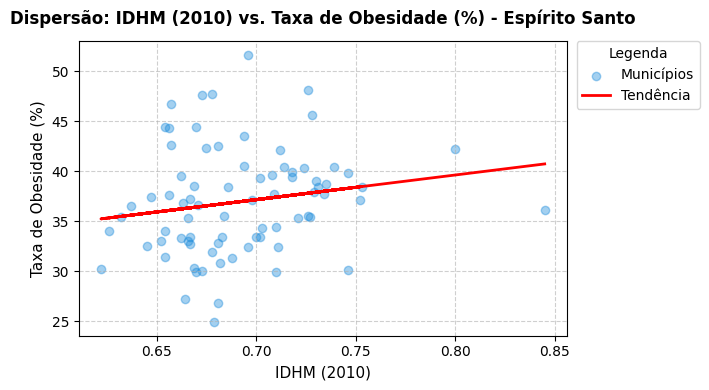

In [101]:
grafico_IDHM_Obesidade(df_consolidado_es, 'Espírito Santo')

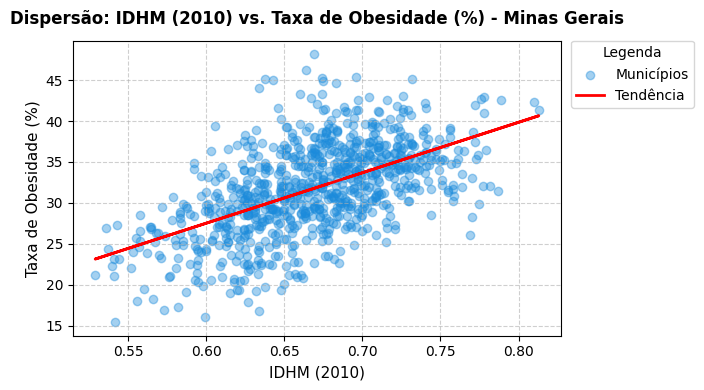

In [102]:
grafico_IDHM_Obesidade(df_consolidado_mg, 'Minas Gerais')

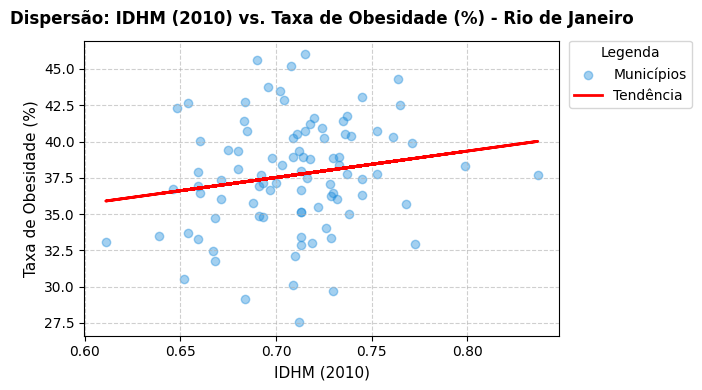

In [103]:
grafico_IDHM_Obesidade(df_consolidado_rj, 'Rio de Janeiro')

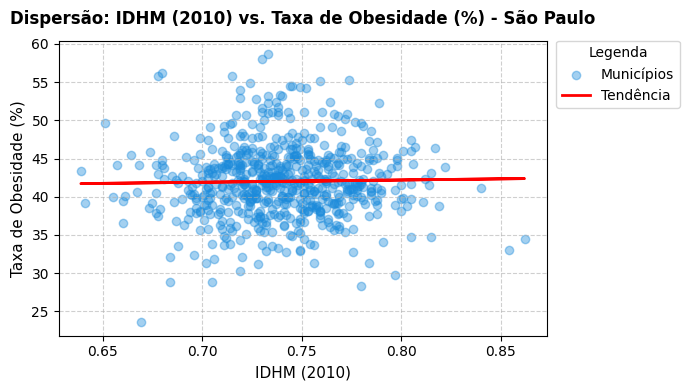

In [104]:
grafico_IDHM_Obesidade(df_tratado_sp, 'São Paulo')

### Verificação da relação dos Graus de Obesidade e do IDHM 2020 - 2025

In [105]:
analise_por_grau_obesidade_es = analise_por_grau_obesidade(df_consolidado_es, 'Espírito Santo')

analise_por_grau_obesidade_es

,Obesidade Grau I %,Obesidade Grau II %,Obesidade Grau III %
faixa_idhm,,,
Médio,21.28,9.52,5.64
Alto,21.86,9.91,6.01
Muito Alto,22.00,10.36,6.86


In [106]:
analise_por_grau_obesidade_mg = analise_por_grau_obesidade(df_consolidado_mg, 'Minas Gerais')

analise_por_grau_obesidade_mg

,Obesidade Grau I %,Obesidade Grau II %,Obesidade Grau III %
faixa_idhm,,,
Baixo,16.86,5.64,5.75
Médio,19.52,7.73,4.65
Alto,20.81,8.89,5.22
Muito Alto,22.60,11.46,7.73


In [107]:
analise_por_grau_obesidade_rj = analise_por_grau_obesidade(df_consolidado_rj, 'Rio de Janeiro')

analise_por_grau_obesidade_rj

,Obesidade Grau I %,Obesidade Grau II %,Obesidade Grau III %
faixa_idhm,,,
Médio,21.41,9.79,5.94
Alto,21.75,10.18,6.11
Muito Alto,21.83,9.92,5.98


In [108]:
analise_por_grau_obesidade_sp = analise_por_grau_obesidade(df_tratado_sp, 'São Paulo')

analise_por_grau_obesidade_sp

,Obesidade Grau I %,Obesidade Grau II %,Obesidade Grau III %
faixa_idhm,,,
Médio,23.14,11.06,7.00
Alto,23.34,11.39,7.66
Muito Alto,22.86,10.95,7.15


### Análise da evolução anual de um Grau específico de obesidade em relação as faixas de IDHM

In [109]:
evolucao_anual_grauI_mg = evolucao_anual_grau(df_consolidado_mg, 'Obesidade Grau I %', 'Minas Gerais')

evolucao_anual_grauI_mg

ano,2020,2021,2022,2023,2024,2025
faixa_idhm,,,,,,
Baixo,16.24,16.49,16.16,16.32,17.38,18.58
Médio,19.15,19.38,18.84,19.20,19.77,20.77
Alto,20.48,20.81,20.09,20.47,21.06,21.95
Muito Alto,22.41,23.21,22.37,22.30,22.30,23.02


In [136]:
evolucao_anual_grauII_mg = evolucao_anual_grau(df_consolidado_mg, 'Obesidade Grau II %', 'Minas Gerais')

evolucao_anual_grauII_mg

ano,2020,2021,2022,2023,2024,2025
faixa_idhm,,,,,,
Baixo,5.51,5.31,5.16,5.45,5.90,6.51
Médio,7.36,7.95,7.39,7.47,7.81,8.39
Alto,8.62,9.29,8.37,8.67,8.99,9.40
Muito Alto,10.88,12.38,11.44,11.17,11.21,11.68


In [135]:
evolucao_anual_grauIII_mg = evolucao_anual_grau(df_consolidado_mg, 'Obesidade Grau III %', 'Minas Gerais')

evolucao_anual_grauIII_mg

ano,2020,2021,2022,2023,2024,2025
faixa_idhm,,,,,,
Baixo,9.28,5.69,7.89,5.23,3.51,2.94
Médio,5.24,5.32,4.23,4.14,4.36,4.58
Alto,5.05,6.22,4.64,4.87,5.10,5.45
Muito Alto,6.54,10.22,7.23,7.29,7.54,7.56


In [110]:
evolucao_anual_grauI_es = evolucao_anual_grau(df_consolidado_es, 'Obesidade Grau I %', 'Espiríto Santo')

evolucao_anual_grauI_es

ano,2020,2021,2022,2023,2024,2025
faixa_idhm,,,,,,
Médio,20.25,20.94,20.58,21.07,21.71,23.14
Alto,21.27,20.51,21.28,21.95,22.67,23.47
Muito Alto,22.20,21.81,22.22,21.92,21.90,21.92


In [134]:
evolucao_anual_grauII_es = evolucao_anual_grau(df_consolidado_es, 'Obesidade Grau II %', 'Espiríto Santo')

evolucao_anual_grauII_es

ano,2020,2021,2022,2023,2024,2025
faixa_idhm,,,,,,
Médio,8.62,9.50,8.89,9.46,9.94,10.69
Alto,8.60,9.54,9.48,10.20,10.79,10.83
Muito Alto,9.71,11.28,10.43,10.49,10.32,9.94


In [133]:
evolucao_anual_grauIII_es = evolucao_anual_grau(df_consolidado_es, 'Obesidade Grau III %', 'Espiríto Santo')

evolucao_anual_grauIII_es

ano,2020,2021,2022,2023,2024,2025
faixa_idhm,,,,,,
Médio,4.62,6.69,5.17,5.54,5.70,6.08
Alto,4.91,6.57,5.39,6.29,6.43,6.45
Muito Alto,5.58,10.43,6.29,6.79,6.14,5.93


In [119]:
evolucao_anual_grauI_rj = evolucao_anual_grau(df_consolidado_rj, 'Obesidade Grau I %', 'Rio de Janeiro')

evolucao_anual_grauI_rj

ano,2020,2021,2022,2023,2024,2025
faixa_idhm,,,,,,
Médio,21.50,20.52,20.76,21.30,21.82,22.52
Alto,21.13,21.23,21.38,21.57,22.27,22.89
Muito Alto,21.58,21.76,20.86,21.48,22.46,22.82


In [132]:
evolucao_anual_grauII_rj = evolucao_anual_grau(df_consolidado_rj, 'Obesidade Grau II %', 'Rio de Janeiro')

evolucao_anual_grauII_rj

ano,2020,2021,2022,2023,2024,2025
faixa_idhm,,,,,,
Médio,9.56,9.86,9.30,9.37,10.08,10.54
Alto,10.11,9.87,9.80,9.98,10.40,10.91
Muito Alto,9.63,10.00,9.19,9.86,9.95,10.88


In [131]:
evolucao_anual_grauIII_rj = evolucao_anual_grau(df_consolidado_rj, 'Obesidade Grau III %', 'Rio de Janeiro')

evolucao_anual_grauIII_rj

ano,2020,2021,2022,2023,2024,2025
faixa_idhm,,,,,,
Médio,5.81,6.36,5.55,5.78,5.87,6.26
Alto,5.90,6.02,5.64,5.99,6.46,6.64
Muito Alto,5.51,5.88,5.56,5.98,6.32,6.61


In [ ]:
evolucao_anual_grauI_sp = evolucao_anual_grau(df_tratado_sp, 'Obesidade Grau I %', 'São Paulo')

evolucao_anual_grauI_sp

ano,2020,2021,2022,2023,2024,2025
faixa_idhm,,,,,,
Médio,23.35,22.48,22.66,23.20,23.42,23.71
Alto,23.72,22.84,22.83,22.98,23.46,24.19
Muito Alto,23.11,22.70,22.44,22.45,22.83,23.63


In [129]:
evolucao_anual_grauII_sp = evolucao_anual_grau(df_tratado_sp, 'Obesidade Grau II %', 'São Paulo')

evolucao_anual_grauII_sp

ano,2020,2021,2022,2023,2024,2025
faixa_idhm,,,,,,
Médio,11.79,11.31,10.37,10.78,10.85,11.23
Alto,11.43,11.71,10.94,11.17,11.46,11.62
Muito Alto,10.92,11.05,10.55,10.63,11.06,11.51


In [130]:
evolucao_anual_grauIII_sp = evolucao_anual_grau(df_tratado_sp, 'Obesidade Grau III %', 'São Paulo')

evolucao_anual_grauIII_sp

ano,2020,2021,2022,2023,2024,2025
faixa_idhm,,,,,,
Médio,6.43,9.03,6.28,6.63,6.67,6.98
Alto,7.17,9.23,7.00,7.43,7.72,7.43
Muito Alto,6.81,7.90,6.66,7.01,7.15,7.39


### Gráfico e tabela da Prevalência agregada de obesidade entre os indivíduos avaliados no SISVAN 

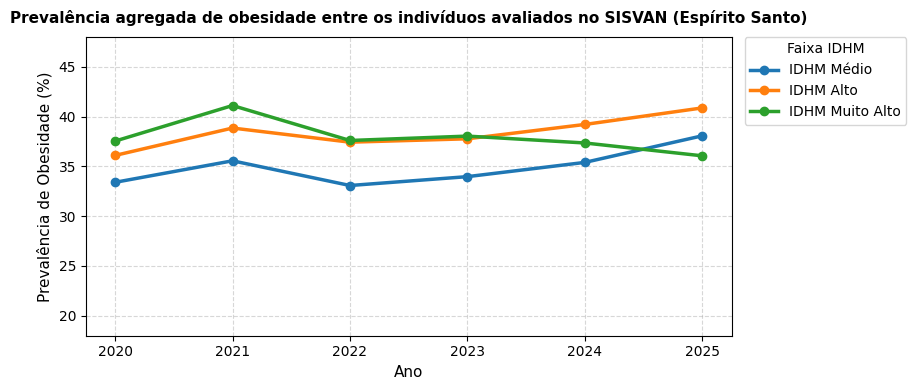

obesidade_total   Total  prevalencia %
ano  faixa_idhm                                        
2020 Médio                 10107   30261          33.40
     Alto                  23472   65018          36.10
     Muito Alto             6252   16655          37.54
2021 Médio                 16410   46142          35.56
     Alto                  29780   76658          38.85
     Muito Alto            11281   27439          41.11
2022 Médio                 21270   64294          33.08
     Alto                  53033  141673          37.43
     Muito Alto            15711   41788          37.60
2023 Médio                 25805   75960          33.97
     Alto                  67811  179545          37.77
     Muito Alto            18785   49384          38.04
2024 Médio                 25646   72441          35.40
     Alto                  78613  200495          39.21
     Muito Alto            32189   86186          37.35
2025 Médio                 37135   97556          38.07
     Alto                  98641  241348          40.87
     Muito Alto            50308  139526          36.06

In [147]:
prevalencia_agregada_es = prevalencia_agregada(df_consolidado_es, 'Espírito Santo')

prevalencia_agregada_es

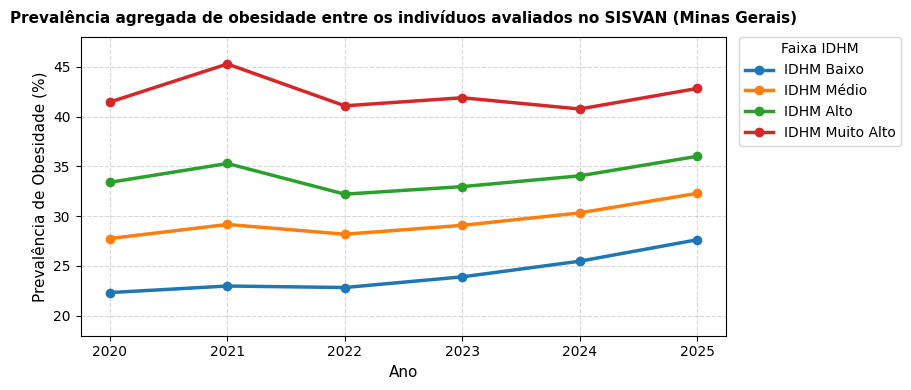

obesidade_total    Total  prevalencia %
ano  faixa_idhm                                         
2020 Baixo                 22672   101522          22.33
     Médio                203759   734021          27.76
     Alto                 256054   766652          33.40
     Muito Alto            30078    72545          41.46
2021 Baixo                 25292   110013          22.99
     Médio                228776   784160          29.17
     Alto                 299505   848736          35.29
     Muito Alto            34186    75504          45.28
2022 Baixo                 31894   139638          22.84
     Médio                308455  1094310          28.19
     Alto                 399607  1240571          32.21
     Muito Alto            35310    85956          41.08
2023 Baixo                 33978   142111          23.91
     Médio                357784  1230158          29.08
     Alto                 487860  1479548          32.97
     Muito Alto            38307    91445          41.89
2024 Baixo                 37614   147595          25.48
     Médio                394372  1300466          30.33
     Alto                 553681  1626317          34.05
     Muito Alto            24413    59888          40.76
2025 Baixo                 45179   163503          27.63
     Médio                462880  1433624          32.29
     Alto                 640714  1779320          36.01
     Muito Alto            27702    64699          42.82

In [143]:
prevalencia_agregada_mg = prevalencia_agregada(df_consolidado_mg, 'Minas Gerais')

prevalencia_agregada_mg

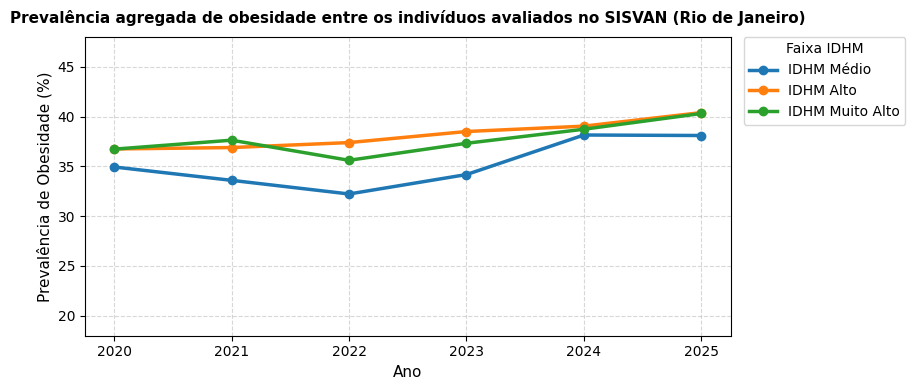

obesidade_total    Total  prevalencia %
ano  faixa_idhm                                         
2020 Médio                 13000    37207          34.94
     Alto                 156523   425891          36.75
     Muito Alto             3999    10889          36.73
2021 Médio                 17838    53082          33.60
     Alto                 196836   533598          36.89
     Muito Alto             3388     9004          37.63
2022 Médio                 30077    93319          32.23
     Alto                 333369   891662          37.39
     Muito Alto             4973    13967          35.61
2023 Médio                 41731   122091          34.18
     Alto                 466743  1212285          38.50
     Muito Alto             9178    24591          37.32
2024 Médio                 56161   147226          38.15
     Alto                 572571  1466493          39.04
     Muito Alto            15892    41036          38.73
2025 Médio                 76720   201371          38.10
     Alto                 731489  1810665          40.40
     Muito Alto            19246    47745          40.31

In [144]:
prevalencia_agregada_rj = prevalencia_agregada(df_consolidado_rj, 'Rio de Janeiro')

prevalencia_agregada_rj

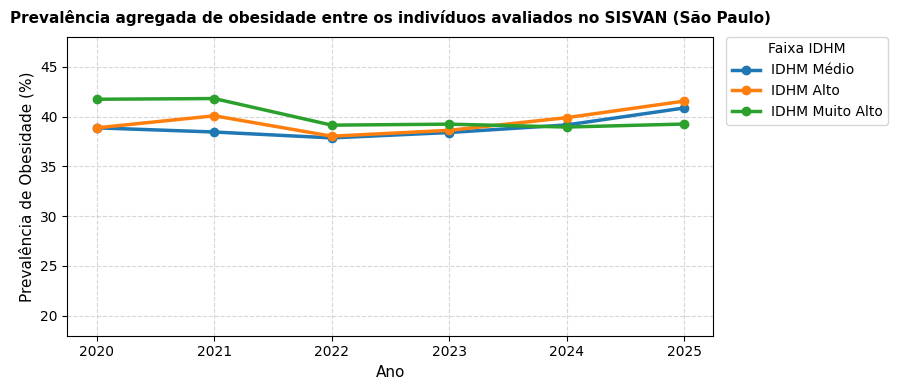

obesidade_total    Total  prevalencia %
ano  faixa_idhm                                         
2020 Médio                 12774    32863          38.87
     Alto                 310905   799914          38.87
     Muito Alto           152522   365418          41.74
2021 Médio                 16311    42421          38.45
     Alto                 437466  1091405          40.08
     Muito Alto           211888   506834          41.81
2022 Médio                 28173    74417          37.86
     Alto                 648087  1704277          38.03
     Muito Alto           337937   863371          39.14
2023 Médio                 34500    89841          38.40
     Alto                 800531  2073054          38.62
     Muito Alto           444062  1131636          39.24
2024 Médio                 41862   106894          39.16
     Alto                 958270  2402030          39.89
     Muito Alto           507342  1302481          38.95
2025 Médio                 52318   128049          40.86
     Alto                1210310  2913023          41.55
     Muito Alto           626455  1595973          39.25

In [145]:
prevalencia_agregada_sp = prevalencia_agregada(df_tratado_sp, 'São Paulo')

prevalencia_agregada_sp

### Nomes dos municípios na faixa de IDHM Muito Alto

In [115]:
cidades_idhm_sp = nome_municipio_por_IDHM(df_tratado_sp, 'Muito Alto')

cidades_idhm_sp

,municipio_norm,faixa_idhm,idhm_2010
6,AGUAS DE SAO PEDRO,Muito Alto,0.854
18,AMERICANA,Muito Alto,0.811
36,ARARAQUARA,Muito Alto,0.815
46,ASSIS,Muito Alto,0.805
67,BAURU,Muito Alto,0.801
85,BOTUCATU,Muito Alto,0.800
108,CAMPINAS,Muito Alto,0.805
235,ILHA SOLTEIRA,Muito Alto,0.812
295,JUNDIAI,Muito Alto,0.822
441,PIRASSUNUNGA,Muito Alto,0.801


In [116]:
cidades_idhm_es = nome_municipio_por_IDHM(df_consolidado_es, 'Muito Alto')

cidades_idhm_es

,municipio_norm,faixa_idhm,idhm_2010
76,VILA VELHA,Muito Alto,0.800
77,VITORIA,Muito Alto,0.845


In [117]:
cidades_idhm_mg = nome_municipio_por_IDHM(df_consolidado_mg, 'Muito Alto')

cidades_idhm_mg

,municipio_norm,faixa_idhm,idhm_2010
64,BELO HORIZONTE,Muito Alto,0.810
517,NOVA LIMA,Muito Alto,0.813


In [118]:
cidades_idhm_rj = nome_municipio_por_IDHM(df_consolidado_rj, 'Muito Alto')

cidades_idhm_rj

,municipio_norm,faixa_idhm,idhm_2010
47,NITEROI,Muito Alto,0.837


### **Análise dos dados integrados da Região Sudeste**


In [162]:
analise_exp_sudeste = comparar_idhm(df_sudeste)

analise_exp_sudeste

,Faixa do IDHM,Número de Municípios,Número de observações (2020-2025),Média da Taxa de Obesidade (%),Mediana da Taxa de Obesidade (%),Desvio-padrão da Taxa de Obesidade (%),Valor máximo da Taxa de Obesidade (%),Valor mínimo da Taxa de Obesidade (%)
0,Baixo,73,438,24.80,24.68,4.98,53.33,0.00
1,Médio,691,4152,32.74,32.36,7.05,100.00,9.62
2,Alto,869,5209,39.88,39.82,7.02,100.00,0.00
3,Muito Alto,29,174,40.79,40.80,4.43,51.65,30.97


In [163]:
media_anual_sudeste = media_anual_obesidade(df_sudeste)

media_anual_sudeste

ano,2020,2021,2022,2023,2024,2025
faixa_idhm,,,,,,
Baixo,23.82,23.74,23.41,24.06,25.77,28.03
Médio,31.73,33.18,31.33,32.06,33.13,35.03
Alto,39.25,40.90,38.29,39.23,40.30,41.30
Muito Alto,40.39,41.93,39.55,39.98,40.79,42.10


In [164]:
mediana_anual_sudeste = mediana_anual_obesidade(df_sudeste)

media_anual_sudeste

ano,2020,2021,2022,2023,2024,2025
faixa_idhm,,,,,,
Baixo,23.82,23.74,23.41,24.06,25.77,28.03
Médio,31.73,33.18,31.33,32.06,33.13,35.03
Alto,39.25,40.90,38.29,39.23,40.30,41.30
Muito Alto,40.39,41.93,39.55,39.98,40.79,42.10


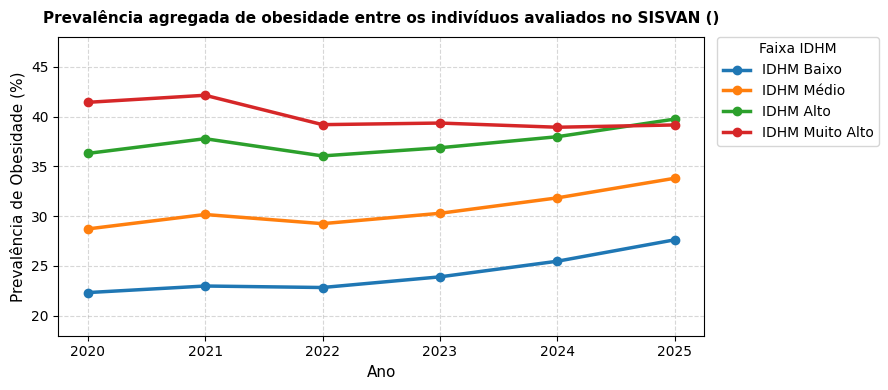

obesidade_total    Total  prevalencia %
ano  faixa_idhm                                         
2020 Baixo                 22672   101522          22.33
     Médio                239640   834352          28.72
     Alto                 746954  2057475          36.30
     Muito Alto           192851   465507          41.43
2021 Baixo                 25292   110013          22.99
     Médio                279335   925805          30.17
     Alto                 963587  2550397          37.78
     Muito Alto           260743   618781          42.14
2022 Baixo                 31894   139638          22.84
     Médio                387975  1326340          29.25
     Alto                1434096  3978183          36.05
     Muito Alto           393931  1005082          39.19
2023 Baixo                 33978   142111          23.91
     Médio                459820  1518050          30.29
     Alto                1822945  4944432          36.87
     Muito Alto           510332  1297056          39.35
2024 Baixo                 37614   147595          25.48
     Médio                518041  1627027          31.84
     Alto                2163135  5695335          37.98
     Muito Alto           579836  1489591          38.93
2025 Baixo                 45179   163503          27.63
     Médio                629053  1860600          33.81
     Alto                2681154  6744356          39.75
     Muito Alto           723711  1847943          39.16

In [169]:
prevalencia_agregada_sudeste = prevalencia_agregada_sudeste(df_sudeste)

prevalencia_agregada_sudeste

### **Análise de Spearman** para verificar se existe correlação entre o IDHM e a prevalência da obesidade

In [ ]:
obesidade_media_municipal = (
    df_sudeste.groupby(
        ['UF', 'municipio_norm', 'idhm_2010']
    )['obesidade_total_%']
    .mean()
    .reset_index()
)

obesidade_media_municipal

In [173]:
from scipy.stats import spearmanr

df_correlacao = obesidade_media_municipal[
    ['idhm_2010', 'obesidade_total_%']
].dropna()

coeficiente, p_valor = spearmanr(
    df_correlacao['idhm_2010'],
    df_correlacao['obesidade_total_%']
)

print(f"Coeficiente de Spearman: {coeficiente:.4f}")
print(f"Valor-p: {p_valor:.4f}")

Coeficiente de Spearman: 0.6367
Valor-p: 0.0000
